# Netflix vs. Disney Content Analytics & Intelligence Project
### A statistics, machine learning, and time-series study of streaming catalog data

**Dataset:** `tv_movie_shows.csv` — 9,338 titles (7,926 Netflix / 1,412 Disney), 51 engineered features covering cast, genre, ratings, duration, country, and catalog-addition metadata.

**Project roadmap**
1. Data loading, cleaning & quality checks
2. Exploratory Data Analysis (static + interactive visualizations)
3. **Content growth over time** — time-series analysis, trend tests, decomposition, forecasting
4. Normality testing & data transformation
5. Multiple hypothesis / statistical testing (with multiple-comparison correction)
6. A/B testing framework (Netflix vs. Disney)
7. Machine learning — classification & regression
8. **NLP & text analysis** — topic modeling, keyword differentiation, sentiment
9. **Clustering & segmentation** — do natural content segments cut across platform lines?
10. **Vintage & cohort analysis** — is each platform's acquisition strategy getting fresher or staler?
11. Key findings & recommendations


## 1. Setup & Imports

In [2]:

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"

from scipy import stats

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import TTestIndPower

import pymannkendall as mk

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler, PowerTransformer, LabelEncoder
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                              confusion_matrix, r2_score, mean_squared_error, mean_absolute_error,
                              RocCurveDisplay)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 60)

NETFLIX_COLOR = "#E50914"
DISNEY_COLOR = "#113CCF"
PALETTE = {"Netflix": NETFLIX_COLOR, "Disney": DISNEY_COLOR}

print("Libraries loaded.")


Libraries loaded.


## 2. Data Loading & Overview

In [3]:

df = pd.read_csv("tv_movie_shows.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)


Shape: 9,338 rows x 51 columns


,id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,platform,duration_minutes,num_seasons,year_added,month_added,day_of_week_added,content_age_years,years_between_release_and_added,decade_released,num_cast_members,num_directors,num_countries,num_genres,description_word_count,description_char_count,title_char_count,title_word_count,is_movie,is_netflix,is_multi_country,is_multi_genre,is_us_production,has_director_listed,has_cast_listed,has_country_listed,maturity_level,production_scale_index,cast_per_director,genre_to_cast_ratio,international_scope_score,maturity_x_duration,maturity_x_age,description_to_title_ratio,netflix_movie_flag,disney_tv_flag,freshness_index,freshness_x_maturity,seasons_per_year_since_release,metadata_completeness_score
0,1,Movie,ChuChuTV Surprise Eggs Learning Videos (English),NaN,NaN,NaN,"October 18, 2019",2019,TV-Y,61 min,Children & Family Movies,From colors and letters to animals of all kind...,Netflix,61.0,NaN,2019.0,10.0,4.0,7,0.0,2010,0,0,0,1,26,147,48,6,1,1,0,0,0,0,0,0,0.0,0,0.0,1.000000,0,0.0,0.0,4.333333,1,0,1.00,0.0,NaN,0
1,2,Movie,The Journey Is the Destination,Bronwen Hughes,"Ben Schnetzer, Kelly Macdonald, Sam Hazeldine,...",United States,"November 7, 2017",2016,R,123 min,Dramas,Spirited 22-year-old activist and photojournal...,Netflix,123.0,NaN,2017.0,11.0,1.0,10,1.0,2010,6,1,1,1,22,150,30,5,1,1,0,0,1,1,1,1,3.0,11,3.0,0.142857,1,369.0,30.0,4.400000,1,0,0.50,1.5,NaN,3
2,3,TV Show,Champions,NaN,"Anders Holm, Fortune Feimster, Andy Favreau, J...",United States,"June 19, 2021",2018,TV-14,1 Season,TV Comedies,"Years after getting his girlfriend pregnant, w...",Netflix,NaN,1.0,2021.0,6.0,5.0,8,3.0,2010,9,0,1,1,24,151,9,1,0,1,0,0,1,0,1,1,2.0,12,9.0,0.100000,1,NaN,16.0,24.000000,0,0,0.25,0.5,0.125,2


In [5]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9338 entries, 0 to 9337
Data columns (total 51 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id                               9338 non-null   int64  
 1   type                             9338 non-null   str    
 2   title                            9338 non-null   str    
 3   director                         6483 non-null   str    
 4   cast                             8400 non-null   str    
 5   country                          8376 non-null   str    
 6   date_added                       9325 non-null   str    
 7   release_year                     9338 non-null   int64  
 8   rating                           9328 non-null   str    
 9   duration                         9338 non-null   str    
 10  listed_in                        9338 non-null   str    
 11  description                      9338 non-null   str    
 12  platform                       

In [4]:

df["platform"].value_counts().to_frame("count").assign(pct=lambda d: (d["count"]/d["count"].sum()*100).round(1))


,count,pct
platform,,
Netflix,7926,84.9
Disney,1412,15.1


## 3. Data Cleaning & Preprocessing

Missing values in this dataset are mostly *structural*, not erroneous:
- `duration_minutes` is only populated for movies; `num_seasons` only for TV shows.
- `director`/`cast`/`country` are genuinely unlisted for some titles on the platforms themselves.

We fix data types, parse dates, and build a few analysis-ready fields without destroying that structure.


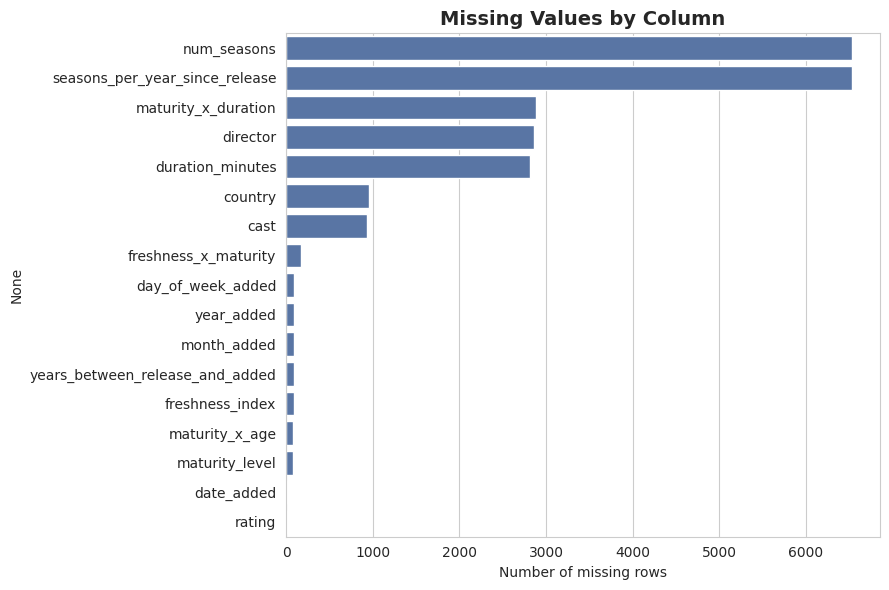

In [5]:

# Missing value overview
miss = df.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=miss.values, y=miss.index, color="#4C72B0", ax=ax)
ax.set_title("Missing Values by Column")
ax.set_xlabel("Number of missing rows")
plt.tight_layout()
plt.show()


In [6]:

# Parse dates & basic type fixes
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
# Keep 'type'/'platform' as plain strings (not pandas Categorical) — several downstream
# groupby/plotly operations don't play well with non-ordered Categorical dtype.

# Duplicate check
dupes = df.duplicated(subset=["title", "release_year", "platform"]).sum()
print(f"Duplicate (title, release_year, platform) rows: {dupes}")

# Fill categorical text NA for genre/country parsing (keep numeric engineered cols untouched)
for c in ["director", "cast", "country", "rating"]:
    df[c] = df[c].fillna("Unknown")

# Rows usable for the time-series work (need a valid add-date)
df_ts = df.dropna(subset=["year_added", "month_added"]).copy()
df_ts["year_added"] = df_ts["year_added"].astype(int)
df_ts["month_added"] = df_ts["month_added"].astype(int)
print(f"Rows with valid add-date: {len(df_ts):,} / {len(df):,}")


Duplicate (title, release_year, platform) rows: 0
Rows with valid add-date: 9,245 / 9,338


In [7]:

# Explode helper columns for genre / country multi-value analysis
genre_exploded = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre")
country_exploded = df[df["country"] != "Unknown"].assign(country_single=df["country"].str.split(", ")).explode("country_single")
print("Exploded genre rows:", len(genre_exploded))
print("Exploded country rows:", len(country_exploded))


Exploded genre rows: 21212
Exploded country rows: 10497


## 4. Exploratory Data Analysis

In-depth static visualizations covering catalog composition, ratings, duration, genres, and countries — always split by platform since Netflix vs. Disney is the recurring axis of comparison.


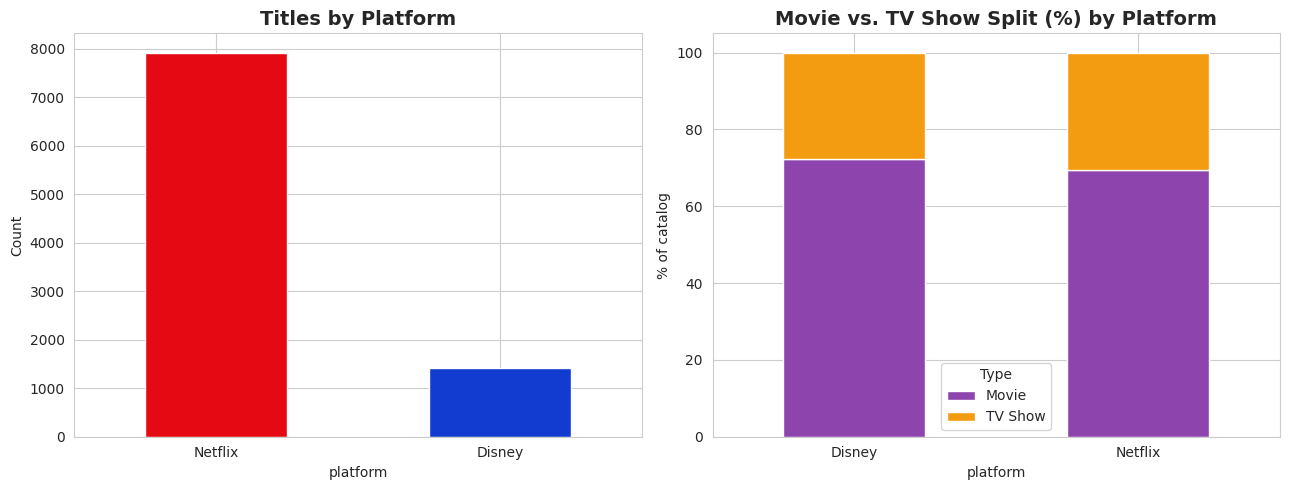

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df["platform"].value_counts().plot(kind="bar", color=[NETFLIX_COLOR, DISNEY_COLOR], ax=axes[0])
axes[0].set_title("Titles by Platform")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

ct = pd.crosstab(df["platform"], df["type"], normalize="index") * 100
ct.plot(kind="bar", stacked=True, ax=axes[1], color=["#8E44AD", "#F39C12"])
axes[1].set_title("Movie vs. TV Show Split (%) by Platform")
axes[1].set_ylabel("% of catalog")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Type")

plt.tight_layout()
plt.show()


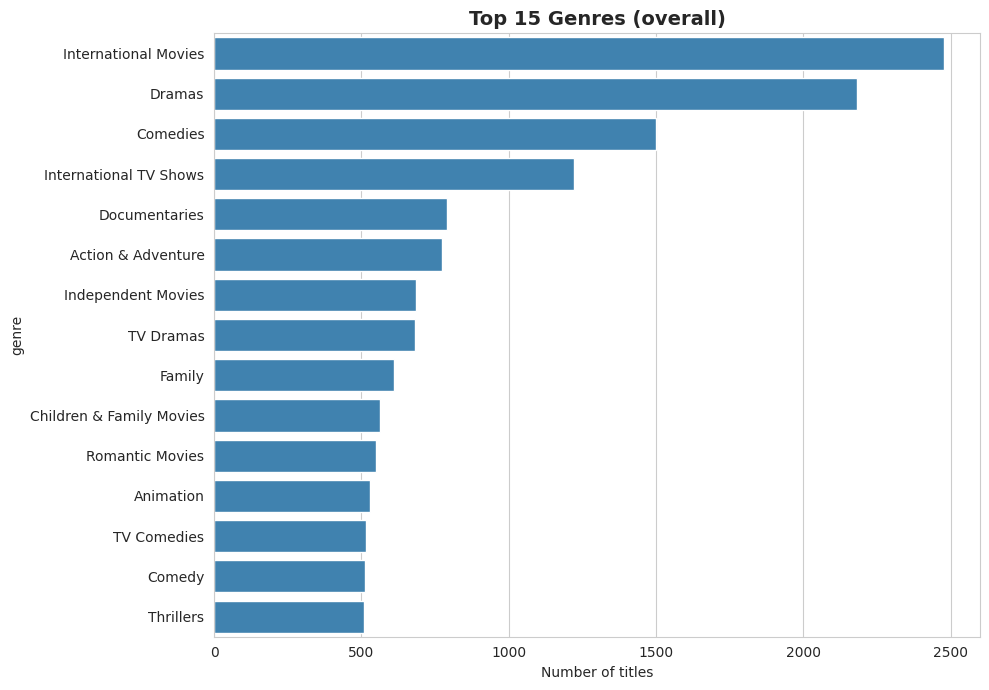

In [9]:

# Top genres overall and by platform
top_genres = genre_exploded["genre"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=top_genres.values, y=top_genres.index, color="#2E86C1", ax=ax)
ax.set_title("Top 15 Genres (overall)")
ax.set_xlabel("Number of titles")
plt.tight_layout()
plt.show()


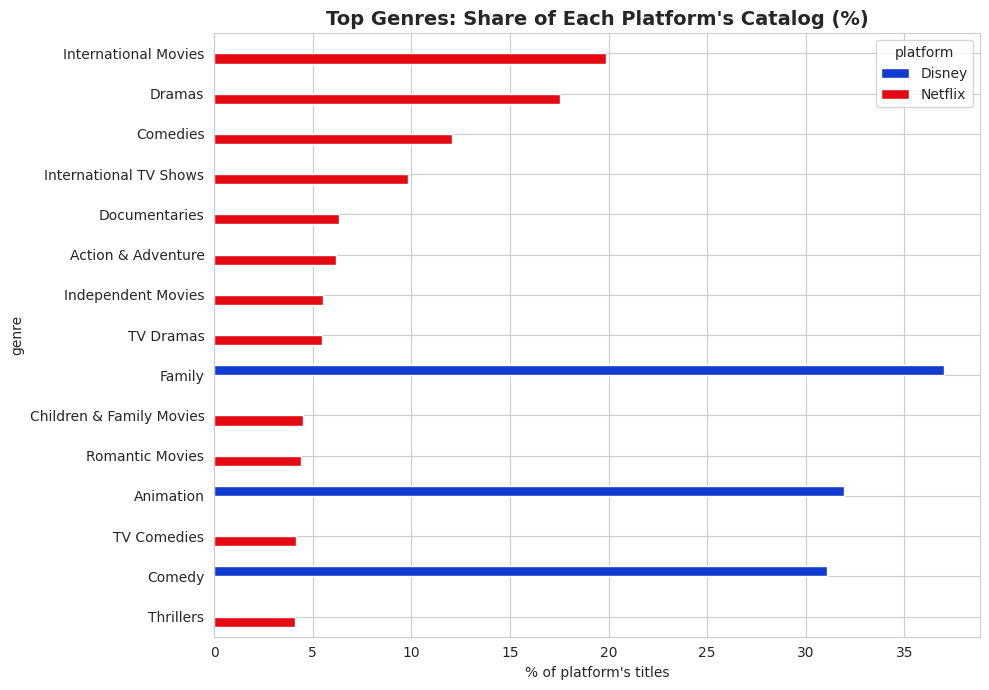

In [10]:

# Top genres split by platform (share within platform)
top_g_names = top_genres.index.tolist()
g_plat = (genre_exploded[genre_exploded["genre"].isin(top_g_names)]
          .groupby(["genre", "platform"]).size().unstack(fill_value=0))
g_plat_pct = g_plat.div(g_plat.sum(axis=0), axis=1) * 100
g_plat_pct = g_plat_pct.loc[top_g_names]

fig, ax = plt.subplots(figsize=(10, 7))
g_plat_pct.plot(kind="barh", ax=ax, color=[DISNEY_COLOR, NETFLIX_COLOR] if "Disney" in g_plat_pct.columns else None)
ax.set_title("Top Genres: Share of Each Platform's Catalog (%)")
ax.set_xlabel("% of platform's titles")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


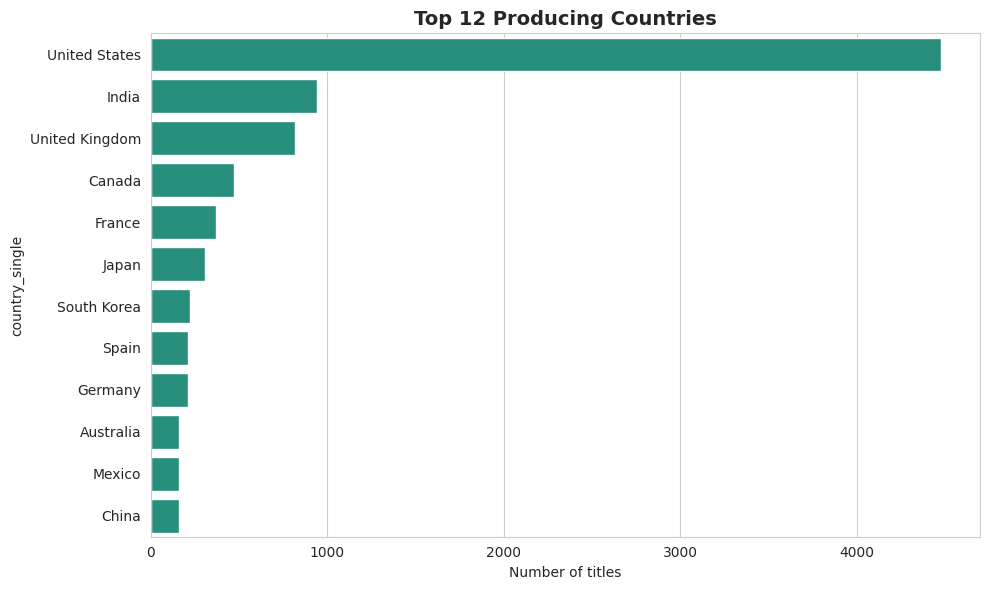

In [11]:

# Top countries of production
top_countries = country_exploded["country_single"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, color="#16A085", ax=ax)
ax.set_title("Top 12 Producing Countries")
ax.set_xlabel("Number of titles")
plt.tight_layout()
plt.show()


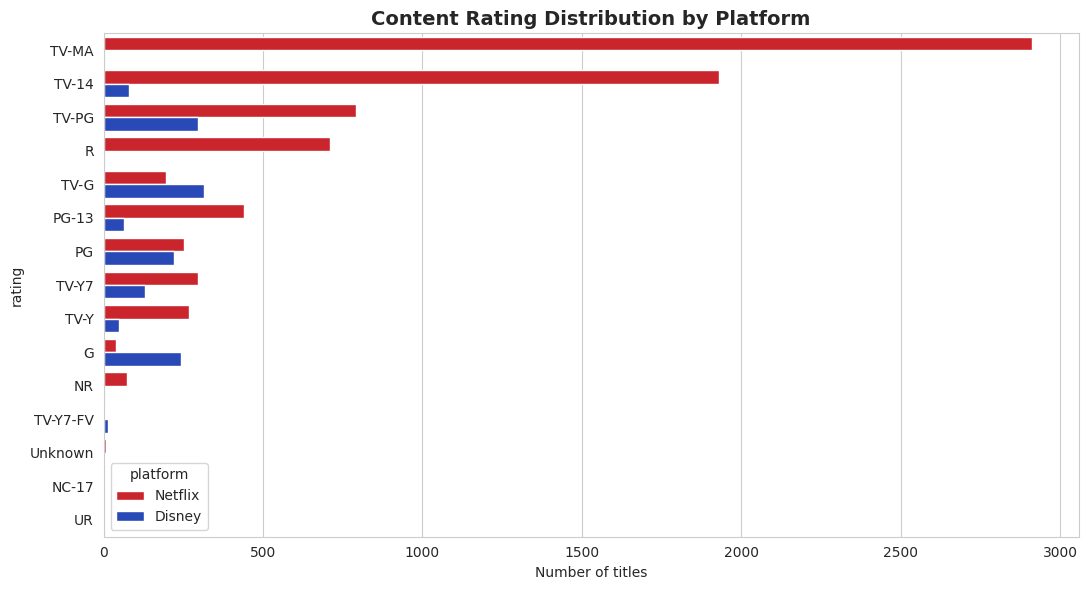

In [12]:

# Rating (maturity) distribution by platform
fig, ax = plt.subplots(figsize=(11, 6))
order = df["rating"].value_counts().index
sns.countplot(data=df, y="rating", hue="platform", order=order, palette=PALETTE, ax=ax)
ax.set_title("Content Rating Distribution by Platform")
ax.set_xlabel("Number of titles")
plt.tight_layout()
plt.show()


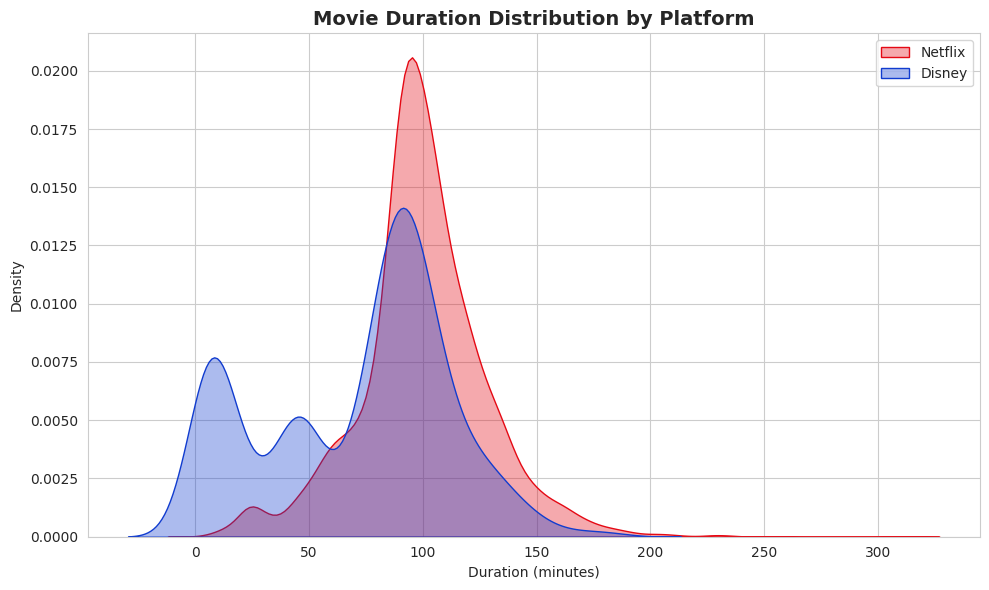

               mean        std  min   50%    max
platform                                        
Disney    71.287671  40.738258  1.0  84.0  183.0
Netflix   99.674900  28.247788  3.0  98.0  312.0


In [13]:

# Movie duration distribution
movies = df[df["is_movie"] == 1]
fig, ax = plt.subplots(figsize=(10, 6))
for plat, color in PALETTE.items():
    sns.kdeplot(movies.loc[movies["platform"] == plat, "duration_minutes"].dropna(),
                label=plat, fill=True, alpha=0.35, color=color, ax=ax)
ax.set_title("Movie Duration Distribution by Platform")
ax.set_xlabel("Duration (minutes)")
ax.legend()
plt.tight_layout()
plt.show()

print(movies.groupby("platform")["duration_minutes"].describe()[["mean","std","min","50%","max"]])


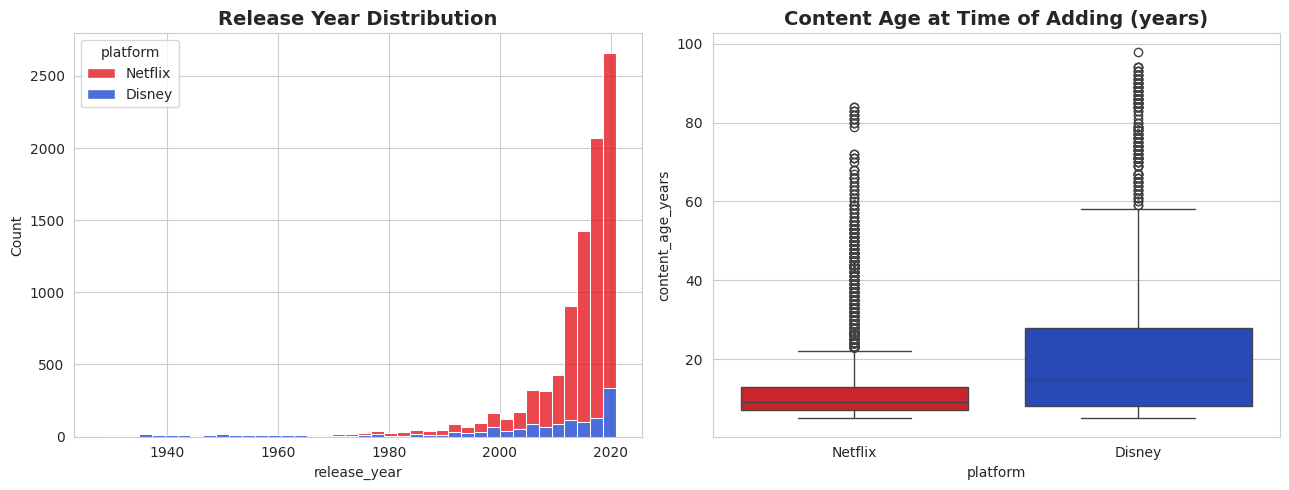

In [14]:

# Release year distribution & content age
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=df, x="release_year", hue="platform", palette=PALETTE, bins=40, ax=axes[0], multiple="stack")
axes[0].set_title("Release Year Distribution")

sns.boxplot(data=df, x="platform", y="content_age_years", palette=PALETTE, ax=axes[1])
axes[1].set_title("Content Age at Time of Adding (years)")
plt.tight_layout()
plt.show()


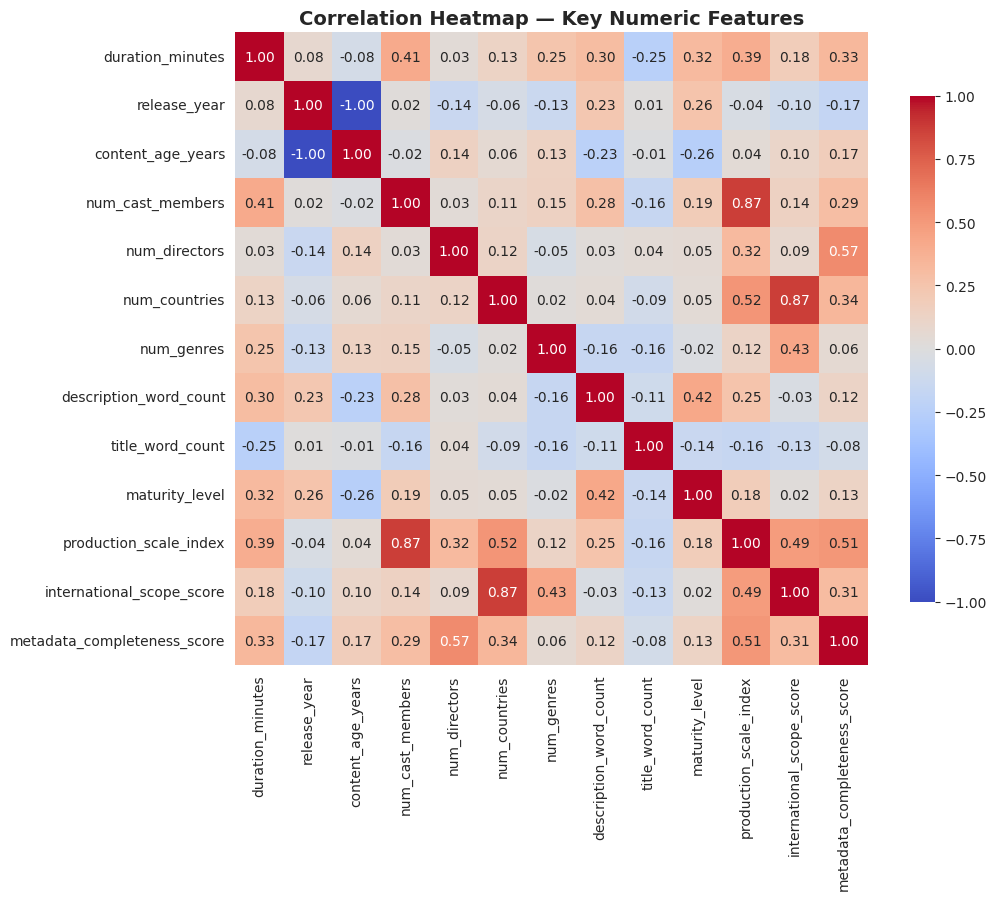

In [15]:

# Correlation heatmap of key numeric features
num_cols = ["duration_minutes", "release_year", "content_age_years", "num_cast_members",
            "num_directors", "num_countries", "num_genres", "description_word_count",
            "title_word_count", "maturity_level", "production_scale_index",
            "international_scope_score", "metadata_completeness_score"]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True,
            cbar_kws={"shrink": .8})
ax.set_title("Correlation Heatmap — Key Numeric Features")
plt.tight_layout()
plt.show()


## 5. Interactive Visualizations (Plotly)

These render inline and support hover, zoom, and legend-toggling — useful for exploring the catalog interactively rather than reading static plots.


In [7]:

# Interactive: titles added per year, by platform
yearly = df_ts.groupby(["year_added", "platform"]).size().reset_index(name="titles_added")
fig = px.line(yearly, x="year_added", y="titles_added", color="platform",
              color_discrete_map=PALETTE, markers=True,
              title="Titles Added per Year, by Platform")
fig.update_layout(xaxis_title="Year added", yaxis_title="Titles added", hovermode="x unified")
fig.show()


In [17]:

# Interactive: cumulative catalog growth
cum = yearly.sort_values("year_added").copy()
cum["cumulative"] = cum.groupby("platform")["titles_added"].cumsum()
fig = px.area(cum, x="year_added", y="cumulative", color="platform",
              color_discrete_map=PALETTE, title="Cumulative Catalog Growth Over Time")
fig.update_layout(xaxis_title="Year added", yaxis_title="Cumulative titles")
fig.show()


In [18]:

# Interactive: sunburst of platform -> type -> rating
sb = df.groupby(["platform", "type", "rating"]).size().reset_index(name="count")
fig = px.sunburst(sb, path=["platform", "type", "rating"], values="count",
                   color="platform", color_discrete_map=PALETTE,
                   title="Catalog Breakdown: Platform → Type → Rating")
fig.update_traces(textinfo="label+percent parent")
fig.show()


In [19]:

# Interactive: treemap of genres by platform
genre_plat_counts = (genre_exploded.groupby(["platform", "genre"]).size()
                      .reset_index(name="count"))
genre_plat_counts = genre_plat_counts[genre_plat_counts["count"] >= 15]
fig = px.treemap(genre_plat_counts, path=["platform", "genre"], values="count",
                  color="platform", color_discrete_map=PALETTE,
                  title="Genre Treemap by Platform (genres with 15+ titles)")
fig.show()


In [20]:

# Interactive: duration by platform, box plot with points
fig = px.box(movies, x="platform", y="duration_minutes", color="platform",
             color_discrete_map=PALETTE, points="outliers",
             title="Movie Duration by Platform (interactive box plot)")
fig.update_layout(showlegend=False)
fig.show()


In [21]:

# Interactive scatter: content age vs cast size, colored by platform, sized by genre count
sample = df.sample(min(3000, len(df)), random_state=42)
fig = px.scatter(sample, x="content_age_years", y="num_cast_members", color="platform",
                  color_discrete_map=PALETTE, size="num_genres", opacity=0.55,
                  hover_data=["title", "release_year", "rating"],
                  title="Content Age vs. Cast Size (bubble = # genres)")
fig.show()


## 6. Content Growth Over Time — Time-Series Analysis

This is the central analytical theme of the project: **how has the catalog grown, and is that growth trending, seasonal, or forecastable?**

We build monthly addition counts per platform, test for trend and stationarity, decompose seasonality, and forecast 12 months ahead.


platform    Disney  Netflix
ym                         
2021-07-01      44      240
2021-08-01      23      154
2021-09-01      36      169
2021-10-01      30        0
2021-11-01      53        0


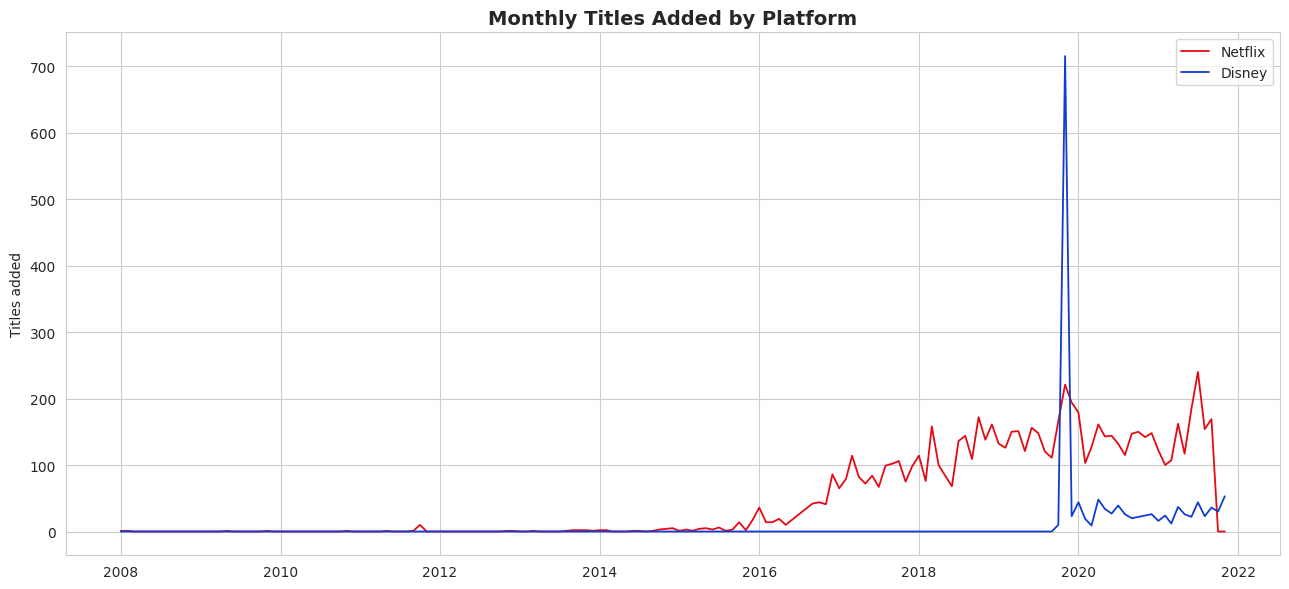

In [22]:

# Build a monthly time series of titles added, per platform
df_ts["ym"] = pd.to_datetime(df_ts["year_added"].astype(str) + "-" + df_ts["month_added"].astype(str) + "-01")

monthly = (df_ts.groupby(["ym", "platform"]).size()
           .unstack(fill_value=0)
           .asfreq("MS", fill_value=0)
           .sort_index())
print(monthly.tail())

fig, ax = plt.subplots(figsize=(13, 6))
for plat, color in PALETTE.items():
    if plat in monthly.columns:
        ax.plot(monthly.index, monthly[plat], label=plat, color=color, linewidth=1.3)
ax.set_title("Monthly Titles Added by Platform")
ax.set_ylabel("Titles added")
ax.legend()
plt.tight_layout()
plt.show()


In [23]:

# Netflix series is long enough for robust decomposition/forecasting; Disney's window is much shorter
netflix_m = monthly["Netflix"]
disney_m = monthly["Disney"] if "Disney" in monthly.columns else None

print("Netflix monthly series length:", len(netflix_m), " span:", netflix_m.index.min(), "->", netflix_m.index.max())
if disney_m is not None:
    print("Disney monthly series length:", len(disney_m), " span:", disney_m.index.min(), "->", disney_m.index.max())


Netflix monthly series length: 167  span: 2008-01-01 00:00:00 -> 2021-11-01 00:00:00
Disney monthly series length: 167  span: 2008-01-01 00:00:00 -> 2021-11-01 00:00:00


In [24]:

# Stationarity: Augmented Dickey-Fuller test
def adf_report(series, name):
    res = adfuller(series.dropna())
    print(f"[ADF] {name}: statistic={res[0]:.3f}, p-value={res[1]:.4f}  "
          f"=> {'Stationary' if res[1] < 0.05 else 'Non-stationary'} (alpha=0.05)")
    return res[1]

adf_report(netflix_m, "Netflix monthly additions")
if disney_m is not None:
    adf_report(disney_m, "Disney monthly additions")


[ADF] Netflix monthly additions: statistic=-0.470, p-value=0.8977  => Non-stationary (alpha=0.05)
[ADF] Disney monthly additions: statistic=-12.069, p-value=0.0000  => Stationary (alpha=0.05)


In [25]:

# Trend significance: Mann-Kendall test (non-parametric, robust to non-normal residuals) on yearly totals
yearly_totals = df_ts.groupby(["year_added", "platform"]).size().unstack(fill_value=0)

for plat in yearly_totals.columns:
    series = yearly_totals[plat]
    # Drop the current partial year if it looks incomplete (fewer than typical months of data)
    result = mk.original_test(series)
    print(f"[Mann-Kendall] {plat}: trend={result.trend}, p-value={result.p:.4f}, "
          f"Sen's slope={result.slope:.2f} titles/year")


[Mann-Kendall] Disney: trend=increasing, p-value=0.0256, Sen's slope=0.00 titles/year
[Mann-Kendall] Netflix: trend=increasing, p-value=0.0001, Sen's slope=134.30 titles/year


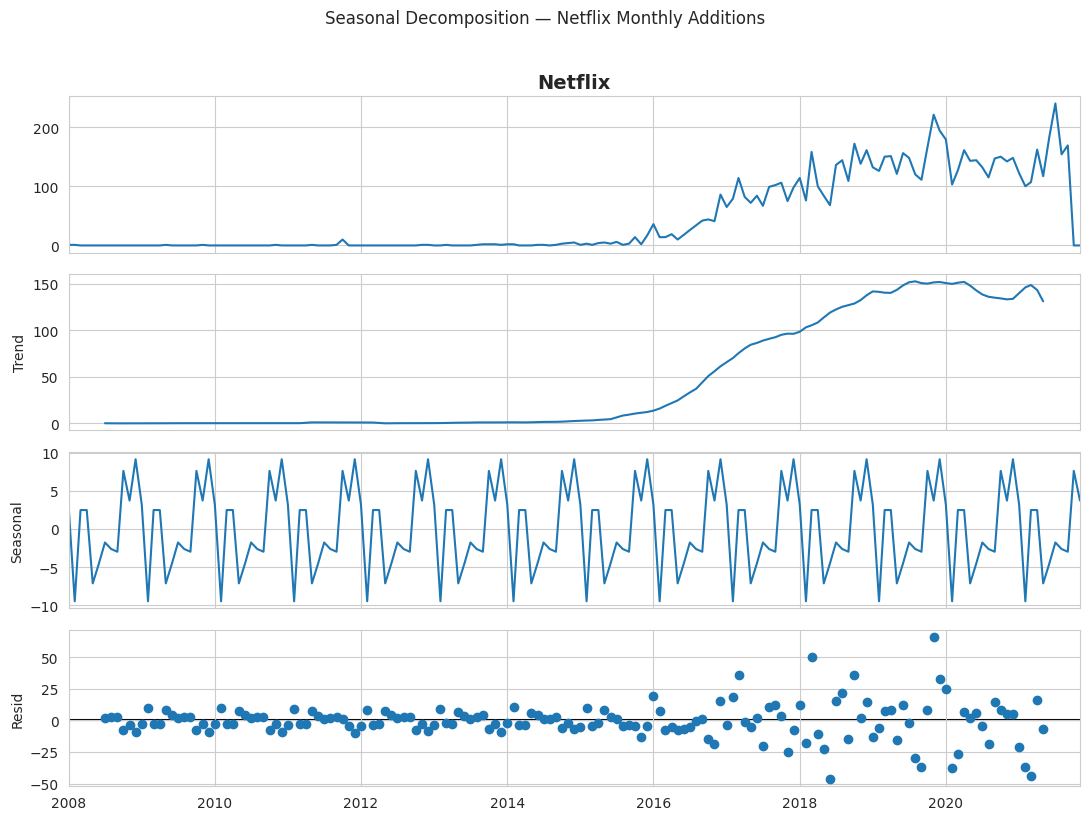

In [26]:

# Seasonal decomposition (additive) of the Netflix monthly series
decomp = seasonal_decompose(netflix_m, model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Seasonal Decomposition — Netflix Monthly Additions", y=1.02)
plt.tight_layout()
plt.show()


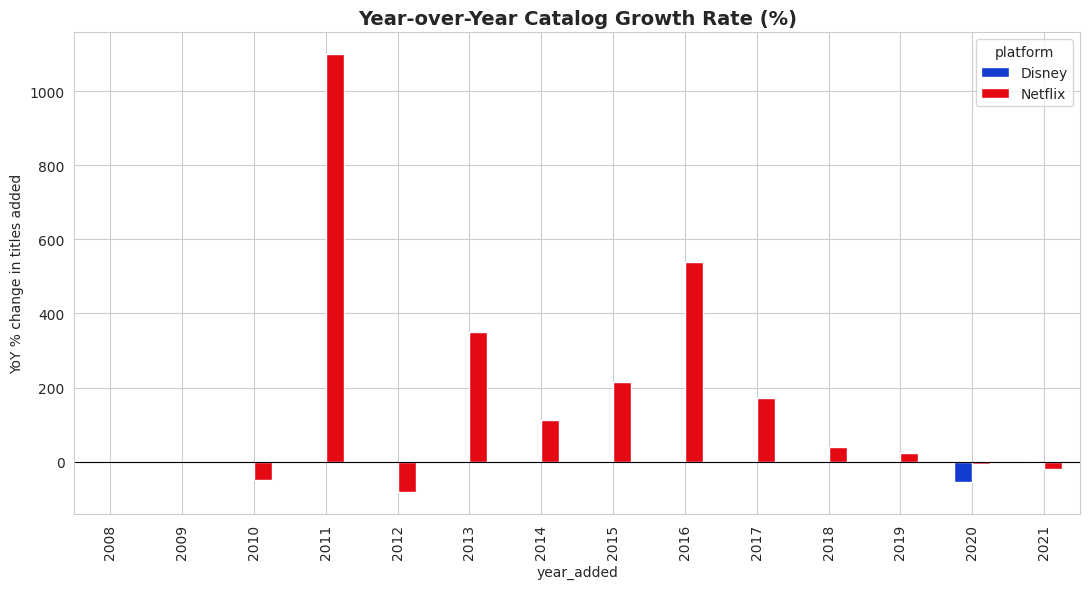

platform,Disney,Netflix
year_added,,
2008,NaN,NaN
2009,NaN,0.0
2010,NaN,-50.0
2011,NaN,1100.0
2012,NaN,-83.3
2013,NaN,350.0
2014,NaN,111.1
2015,NaN,215.8
2016,NaN,540.0


In [27]:

# Year-over-year growth rate comparison
yoy = yearly_totals.pct_change() * 100
fig, ax = plt.subplots(figsize=(11, 6))
yoy.plot(kind="bar", ax=ax, color=[PALETTE.get(c, "gray") for c in yoy.columns])
ax.set_title("Year-over-Year Catalog Growth Rate (%)")
ax.set_ylabel("YoY % change in titles added")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
yoy.round(1)


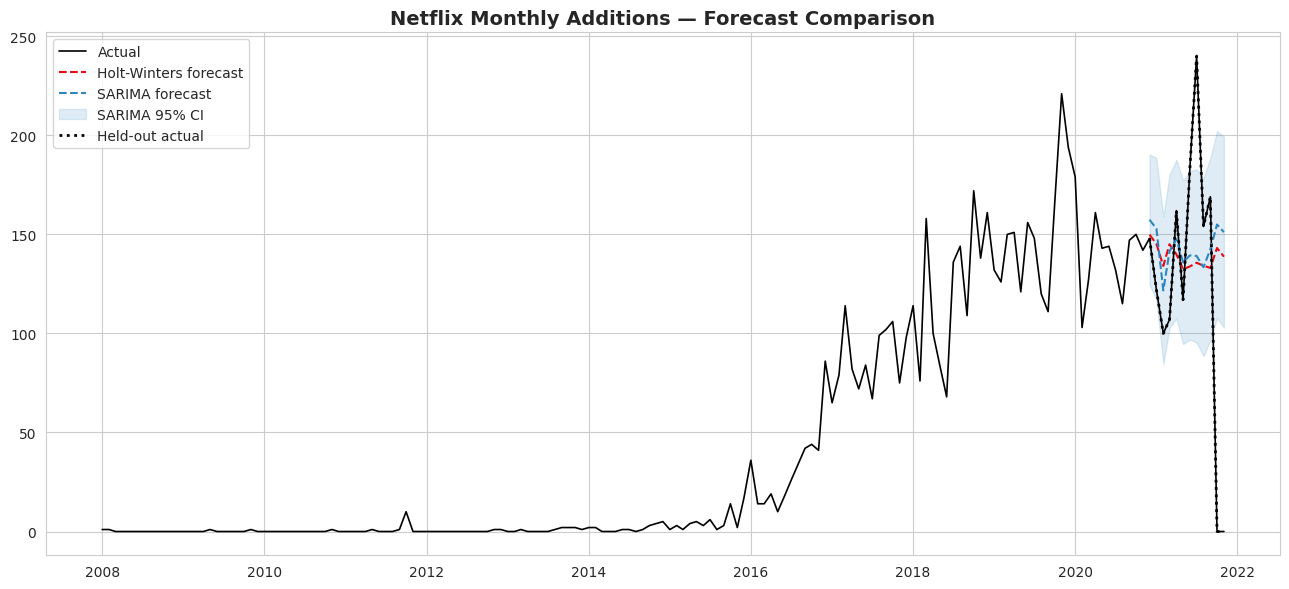

Hold-out RMSE — Holt-Winters: 69.9 | SARIMA: 72.7


In [28]:

# Forecasting: Holt-Winters Exponential Smoothing vs. SARIMA, 12-month-ahead forecast for Netflix
train = netflix_m.iloc[:-12] if len(netflix_m) > 24 else netflix_m
test = netflix_m.iloc[-12:] if len(netflix_m) > 24 else None

hw_model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
hw_forecast = hw_model.forecast(12)

sarima_model = ARIMA(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit()
sarima_forecast = sarima_model.get_forecast(12)
sarima_mean = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(netflix_m.index, netflix_m.values, label="Actual", color="black", linewidth=1.2)
ax.plot(hw_forecast.index, hw_forecast.values, label="Holt-Winters forecast", color=NETFLIX_COLOR, linestyle="--")
ax.plot(sarima_mean.index, sarima_mean.values, label="SARIMA forecast", color="#2E86C1", linestyle="--")
ax.fill_between(sarima_ci.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], color="#2E86C1", alpha=0.15,
                 label="SARIMA 95% CI")
if test is not None:
    ax.plot(test.index, test.values, label="Held-out actual", color="black", linewidth=2, linestyle=":")
ax.set_title("Netflix Monthly Additions — Forecast Comparison")
ax.legend()
plt.tight_layout()
plt.show()

if test is not None:
    hw_rmse = np.sqrt(mean_squared_error(test, hw_forecast))
    sarima_rmse = np.sqrt(mean_squared_error(test, sarima_mean))
    print(f"Hold-out RMSE — Holt-Winters: {hw_rmse:.1f} | SARIMA: {sarima_rmse:.1f}")


**Reading the forecast:** the model with the lower hold-out RMSE is the better short-term forecaster for this series. Given how volatile monthly catalog additions are (they reflect licensing/business decisions, not a smooth organic process), treat the forecast as directional rather than precise — the confidence band is the more honest takeaway than the point forecast.

## 7. Normality Testing & Data Transformation

Before choosing parametric vs. non-parametric tests, we check whether key numeric variables are normally distributed using **Shapiro-Wilk** and **D'Agostino-Pearson** tests, backed by Q-Q plots. Where variables are skewed, we apply a **Box-Cox / Yeo-Johnson power transform** and re-test.


In [1]:

def normality_battery(series, name):
    s = series.dropna()
    # Shapiro-Wilk is unreliable above ~5000 obs; sample for it, use full data for D'Agostino
    shapiro_sample = s.sample(min(len(s), 4999), random_state=42)
    shapiro_stat, shapiro_p = stats.shapiro(shapiro_sample)
    dagostino_stat, dagostino_p = stats.normaltest(s)
    print(f"[{name}] n={len(s)}")
    print(f"  Shapiro-Wilk (sampled): stat={shapiro_stat:.4f}, p={shapiro_p:.4g}")
    print(f"  D'Agostino-Pearson:      stat={dagostino_stat:.4f}, p={dagostino_p:.4g}")
    verdict = "Normal" if (shapiro_p > 0.05 and dagostino_p > 0.05) else "NOT normal"
    print(f"  => {verdict} at alpha=0.05\n")
    return shapiro_p, dagostino_p

vars_to_check = {
    "duration_minutes (movies)": movies["duration_minutes"],
    "content_age_years": df["content_age_years"],
    "num_cast_members": df["num_cast_members"],
}

normality_results = {}
for name, s in vars_to_check.items():
    normality_results[name] = normality_battery(s, name)


NameError: name 'movies' is not defined

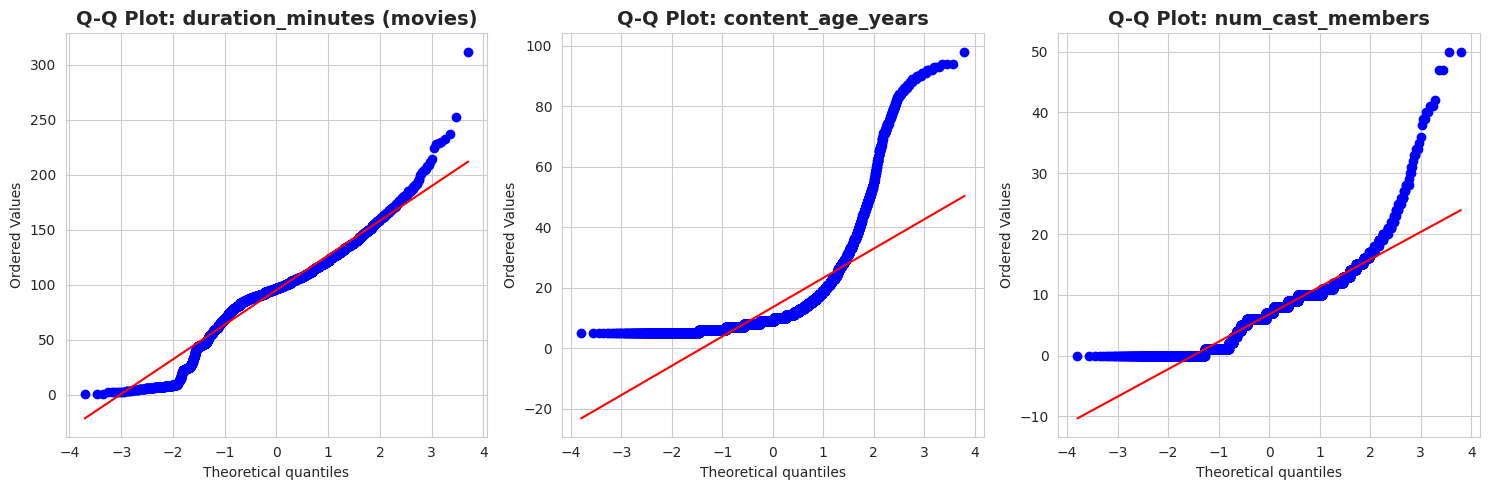

In [30]:

# Q-Q plots for visual confirmation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, s) in zip(axes, vars_to_check.items()):
    stats.probplot(s.dropna(), dist="norm", plot=ax)
    ax.set_title(f"Q-Q Plot: {name}")
plt.tight_layout()
plt.show()


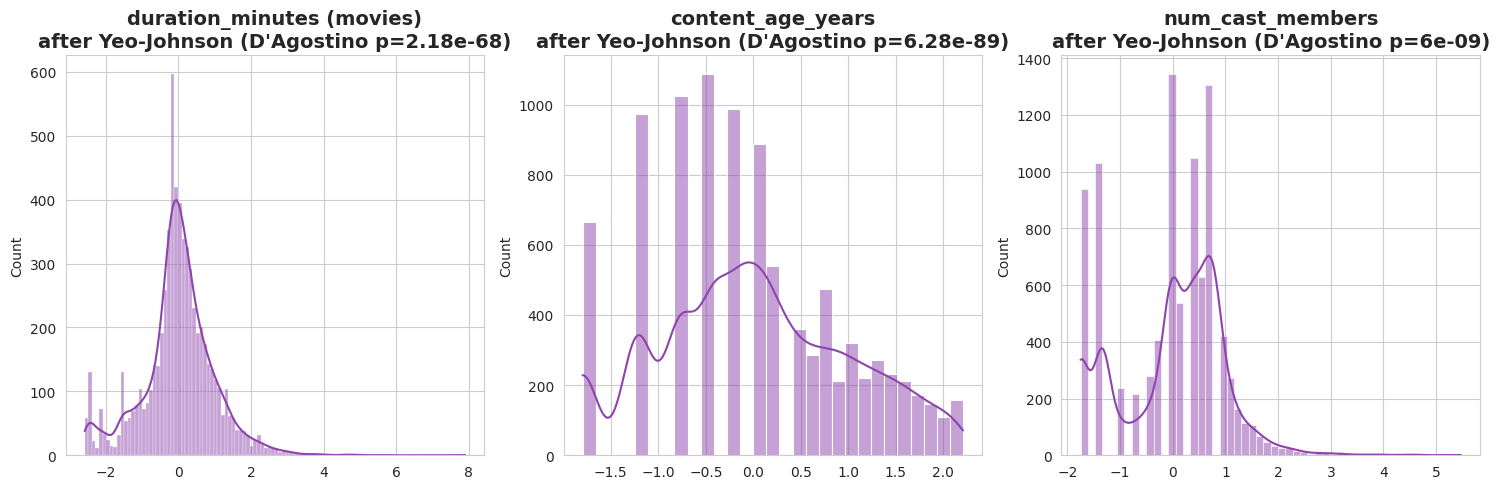

Transformation typically improves symmetry but with catalog-metadata variables like these (heavily driven by business/categorical decisions), full normality is rarely achieved — this is exactly why the hypothesis tests below default to non-parametric alternatives wherever normality fails.


In [31]:

# Apply Yeo-Johnson power transform (handles zeros, unlike Box-Cox) and re-test normality
pt = PowerTransformer(method="yeo-johnson")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, s) in zip(axes, vars_to_check.items()):
    s_clean = s.dropna().values.reshape(-1, 1)
    s_trans = pt.fit_transform(s_clean).flatten()
    sns.histplot(s_trans, kde=True, ax=ax, color="#8E44AD")
    _, p_after = stats.normaltest(s_trans)
    ax.set_title(f"{name}\nafter Yeo-Johnson (D'Agostino p={p_after:.3g})")
plt.tight_layout()
plt.show()
print("Transformation typically improves symmetry but with catalog-metadata variables like these "
      "(heavily driven by business/categorical decisions), full normality is rarely achieved — "
      "this is exactly why the hypothesis tests below default to non-parametric alternatives "
      "wherever normality fails.")


## 8. Multiple Hypothesis / Statistical Testing

We run a battery of tests comparing Netflix vs. Disney and across other groupings, then apply **Benjamini-Hochberg FDR correction** since we're testing many hypotheses at once (running several tests at alpha=0.05 independently inflates the false-positive rate).

| # | Test | Question |
|---|------|----------|
| 1 | Mann-Whitney U | Do movie durations differ between platforms? |
| 2 | Chi-square | Is content type (Movie/TV) associated with platform? |
| 3 | Chi-square | Is content rating associated with platform? |
| 4 | Kruskal-Wallis | Does duration differ across release decades? |
| 5 | Spearman correlation | release_year vs. num_cast_members |
| 6 | Spearman correlation | content_age_years vs. description_word_count |
| 7 | Mann-Whitney U | Does metadata completeness differ between platforms? |


In [32]:

test_results = []  # (name, statistic, p_value)

# 1. Movie duration: Netflix vs Disney (non-parametric since normality failed above)
nf_dur = movies.loc[movies["platform"] == "Netflix", "duration_minutes"].dropna()
dz_dur = movies.loc[movies["platform"] == "Disney", "duration_minutes"].dropna()
u_stat, u_p = stats.mannwhitneyu(nf_dur, dz_dur, alternative="two-sided")
test_results.append(("Duration: Netflix vs Disney (Mann-Whitney U)", u_stat, u_p))
print(f"Mann-Whitney U (duration): stat={u_stat:.1f}, p={u_p:.4g}  "
      f"(Netflix mean={nf_dur.mean():.1f} min, Disney mean={dz_dur.mean():.1f} min)")


Mann-Whitney U (duration): stat=3963377.0, p=6.266e-96  (Netflix mean=99.7 min, Disney mean=71.3 min)


In [33]:

# 2. Content type vs platform
ct_type = pd.crosstab(df["platform"], df["type"])
chi2, p_chi_type, dof, expected = stats.chi2_contingency(ct_type)
test_results.append(("Content type vs Platform (Chi-square)", chi2, p_chi_type))
print(f"Chi-square (type vs platform): chi2={chi2:.2f}, dof={dof}, p={p_chi_type:.4g}")
display(ct_type)


Chi-square (type vs platform): chi2=4.69, dof=1, p=0.03027


type,Movie,TV Show
platform,,
Disney,1022,390
Netflix,5506,2420


In [34]:

# 3. Rating vs platform
ct_rating = pd.crosstab(df["platform"], df["rating"])
chi2r, p_chi_rating, dofr, _ = stats.chi2_contingency(ct_rating)
test_results.append(("Rating vs Platform (Chi-square)", chi2r, p_chi_rating))
print(f"Chi-square (rating vs platform): chi2={chi2r:.2f}, dof={dofr}, p={p_chi_rating:.4g}")


Chi-square (rating vs platform): chi2=3451.77, dof=14, p=0


Kruskal-Wallis (duration by decade): H=406.13, p=6.739e-82


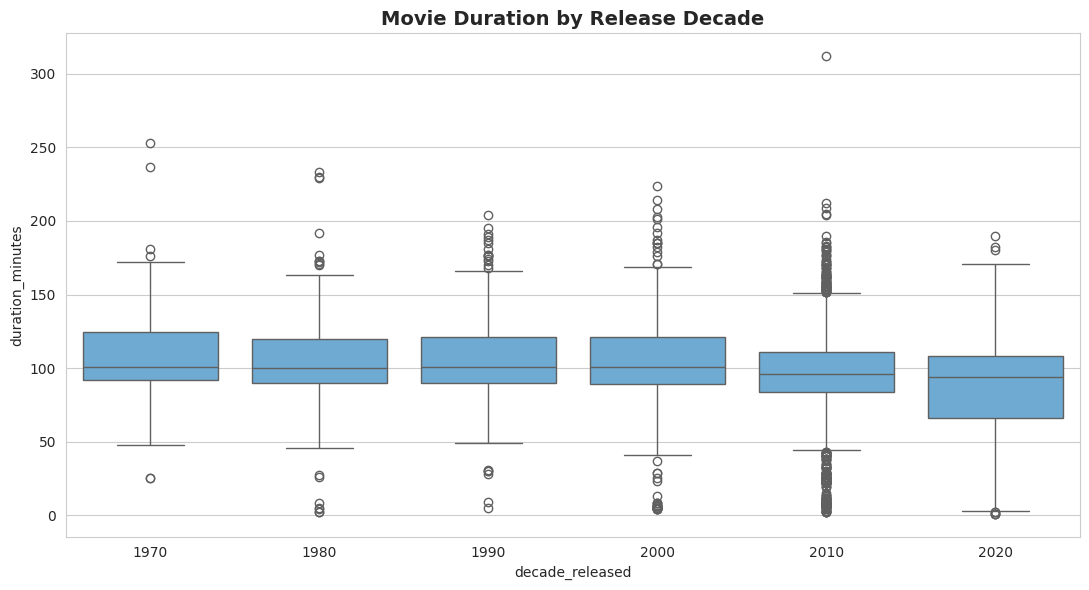

In [35]:

# 4. Duration across release decades (Kruskal-Wallis, non-parametric ANOVA alternative)
decade_groups = [g["duration_minutes"].dropna().values for _, g in movies.groupby("decade_released") if len(g) > 20]
kw_stat, kw_p = stats.kruskal(*decade_groups)
test_results.append(("Duration across decades (Kruskal-Wallis)", kw_stat, kw_p))
print(f"Kruskal-Wallis (duration by decade): H={kw_stat:.2f}, p={kw_p:.4g}")

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=movies[movies["decade_released"] >= 1970], x="decade_released", y="duration_minutes",
            color="#5DADE2", ax=ax)
ax.set_title("Movie Duration by Release Decade")
plt.tight_layout()
plt.show()


In [36]:

# 5 & 6. Correlations
rho1, p1 = stats.spearmanr(df["release_year"], df["num_cast_members"])
test_results.append(("release_year vs num_cast_members (Spearman)", rho1, p1))
print(f"Spearman (release_year vs num_cast_members): rho={rho1:.3f}, p={p1:.4g}")

rho2, p2 = stats.spearmanr(df["content_age_years"], df["description_word_count"])
test_results.append(("content_age_years vs description_word_count (Spearman)", rho2, p2))
print(f"Spearman (content_age vs description_word_count): rho={rho2:.3f}, p={p2:.4g}")


Spearman (release_year vs num_cast_members): rho=-0.084, p=6.156e-16
Spearman (content_age vs description_word_count): rho=-0.122, p=2.013e-32


In [37]:

# 7. Metadata completeness: Netflix vs Disney
nf_meta = df.loc[df["platform"] == "Netflix", "metadata_completeness_score"].dropna()
dz_meta = df.loc[df["platform"] == "Disney", "metadata_completeness_score"].dropna()
u_stat2, u_p2 = stats.mannwhitneyu(nf_meta, dz_meta, alternative="two-sided")
test_results.append(("Metadata completeness: Netflix vs Disney (Mann-Whitney U)", u_stat2, u_p2))
print(f"Mann-Whitney U (metadata completeness): stat={u_stat2:.1f}, p={u_p2:.4g}  "
      f"(Netflix mean={nf_meta.mean():.2f}, Disney mean={dz_meta.mean():.2f})")


Mann-Whitney U (metadata completeness): stat=5952229.5, p=1.125e-05  (Netflix mean=2.51, Disney mean=2.38)


In [38]:

# Multiple-comparison correction (Benjamini-Hochberg FDR)
names = [t[0] for t in test_results]
pvals = [t[2] for t in test_results]
reject, pvals_corrected, _, _ = multipletests(pvals, alpha=0.05, method="fdr_bh")

summary = pd.DataFrame({
    "test": names,
    "raw_p_value": pvals,
    "fdr_corrected_p": pvals_corrected,
    "significant_after_fdr": reject,
}).sort_values("raw_p_value")
summary


,test,raw_p_value,fdr_corrected_p,significant_after_fdr
2,Rating vs Platform (Chi-square),0.000000e+00,0.000000e+00,True
0,Duration: Netflix vs Disney (Mann-Whitney U),6.265850e-96,2.193048e-95,True
3,Duration across decades (Kruskal-Wallis),6.739231e-82,1.572487e-81,True
5,content_age_years vs description_word_count (S...,2.013329e-32,3.523326e-32,True
4,release_year vs num_cast_members (Spearman),6.155540e-16,8.617755e-16,True
6,Metadata completeness: Netflix vs Disney (Mann...,1.125171e-05,1.312700e-05,True
1,Content type vs Platform (Chi-square),3.027373e-02,3.027373e-02,True


**Interpretation:** with 7 simultaneous tests, the Benjamini-Hochberg correction controls the *false discovery rate* rather than letting each test run at a naive alpha=0.05. Any test that survives correction (`significant_after_fdr = True`) is a robust finding, not an artifact of running many comparisons.

## 9. A/B Testing Framework — Netflix (A) vs. Disney (B)

We treat **Netflix as Group A** and **Disney as Group B** and run a proper A/B testing workflow on catalog-strategy metrics: two-proportion z-tests with confidence intervals and effect sizes, plus a power analysis to check whether the sample sizes are even adequate to detect the effects we care about.


In [39]:

def ab_proportion_test(df, flag_col, label):
    a = df.loc[df["platform"] == "Netflix", flag_col]
    b = df.loc[df["platform"] == "Disney", flag_col]
    count = np.array([a.sum(), b.sum()])
    nobs = np.array([len(a), len(b)])
    stat, p = proportions_ztest(count, nobs)
    ci_a = proportion_confint(count[0], nobs[0], method="wilson")
    ci_b = proportion_confint(count[1], nobs[1], method="wilson")
    p_a, p_b = count[0] / nobs[0], count[1] / nobs[1]
    # Cohen's h effect size for two proportions
    h = 2 * np.arcsin(np.sqrt(p_a)) - 2 * np.arcsin(np.sqrt(p_b))
    print(f"--- {label} ---")
    print(f"  Netflix (A): {p_a:.1%}  95% CI [{ci_a[0]:.1%}, {ci_a[1]:.1%}]  (n={nobs[0]:,})")
    print(f"  Disney  (B): {p_b:.1%}  95% CI [{ci_b[0]:.1%}, {ci_b[1]:.1%}]  (n={nobs[1]:,})")
    print(f"  z={stat:.2f}, p={p:.4g}, Cohen's h={h:.3f}  "
          f"({'small' if abs(h)<0.2 else 'medium' if abs(h)<0.5 else 'large'} effect)")
    print()
    return {"metric": label, "p_netflix": p_a, "p_disney": p_b, "z": stat, "p_value": p, "cohens_h": h}

ab_metric_results = []
ab_metric_results.append(ab_proportion_test(df, "is_multi_genre", "Multi-genre listing rate"))
ab_metric_results.append(ab_proportion_test(df, "is_us_production", "US-production rate"))
ab_metric_results.append(ab_proportion_test(df, "is_multi_country", "Multi-country co-production rate"))
ab_metric_results.append(ab_proportion_test(df, "has_director_listed", "Director-listed rate"))


--- Multi-genre listing rate ---
  Netflix (A): 77.1%  95% CI [76.2%, 78.0%]  (n=7,926)
  Disney  (B): 95.5%  95% CI [94.3%, 96.5%]  (n=1,412)
  z=-15.92, p=4.305e-57, Cohen's h=-0.572  (large effect)

--- US-production rate ---
  Netflix (A): 42.0%  95% CI [40.9%, 43.1%]  (n=7,926)
  Disney  (B): 81.4%  95% CI [79.3%, 83.3%]  (n=1,412)
  z=-27.31, p=3.139e-164, Cohen's h=-0.840  (large effect)

--- Multi-country co-production rate ---
  Netflix (A): 15.0%  95% CI [14.2%, 15.8%]  (n=7,926)
  Disney  (B): 12.8%  95% CI [11.2%, 14.7%]  (n=1,412)
  z=2.12, p=0.03369, Cohen's h=0.063  (small effect)

--- Director-listed rate ---
  Netflix (A): 69.8%  95% CI [68.8%, 70.8%]  (n=7,926)
  Disney  (B): 67.1%  95% CI [64.6%, 69.5%]  (n=1,412)
  z=2.09, p=0.03684, Cohen's h=0.060  (small effect)



Metadata completeness score — Netflix mean=2.51, Disney mean=2.38
Welch's t-test: t=5.47, p=5.031e-08
Cohen's d = 0.180 (small effect)


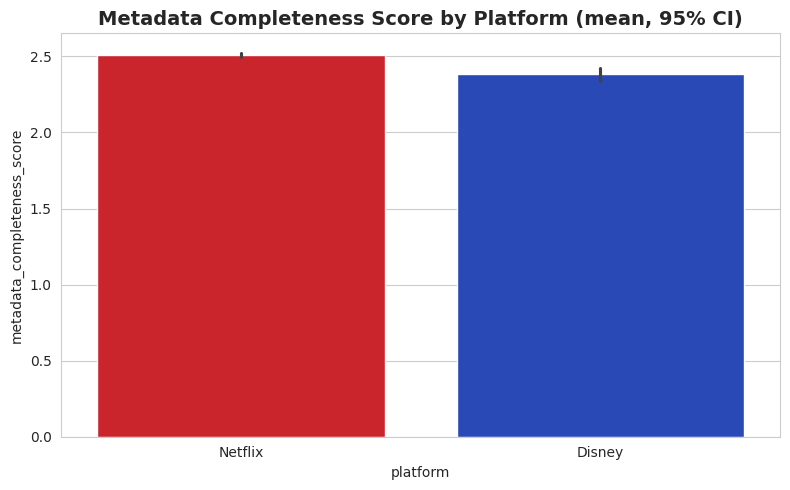

In [40]:

# Continuous-metric A/B test: metadata completeness score (t-test + effect size)
a = df.loc[df["platform"] == "Netflix", "metadata_completeness_score"].dropna()
b = df.loc[df["platform"] == "Disney", "metadata_completeness_score"].dropna()

t_stat, t_p = stats.ttest_ind(a, b, equal_var=False)  # Welch's t-test (unequal variance/sample size safe)
pooled_std = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
cohens_d = (a.mean() - b.mean()) / pooled_std

print(f"Metadata completeness score — Netflix mean={a.mean():.2f}, Disney mean={b.mean():.2f}")
print(f"Welch's t-test: t={t_stat:.2f}, p={t_p:.4g}")
print(f"Cohen's d = {cohens_d:.3f} "
      f"({'small' if abs(cohens_d)<0.2 else 'medium' if abs(cohens_d)<0.5 else 'large'} effect)")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x="platform", y="metadata_completeness_score", palette=PALETTE, ci=95, ax=ax)
ax.set_title("Metadata Completeness Score by Platform (mean, 95% CI)")
plt.tight_layout()
plt.show()


In [41]:

# Statistical power analysis: was the sample size adequate to detect the observed effect?
power_analysis = TTestIndPower()
achieved_power = power_analysis.power(effect_size=cohens_d, nobs1=len(a), ratio=len(b)/len(a), alpha=0.05)
print(f"Achieved statistical power for the metadata-completeness A/B test: {achieved_power:.4f}")

# Required sample size per group to detect a SMALL effect (d=0.2) at 80% power, for future A/B tests
required_n_small = power_analysis.solve_power(effect_size=0.2, alpha=0.05, power=0.8, ratio=1.0)
print(f"Sample size needed per group to reliably detect a small effect (d=0.2) at 80% power: "
      f"~{required_n_small:.0f} titles")


Achieved statistical power for the metadata-completeness A/B test: 1.0000
Sample size needed per group to reliably detect a small effect (d=0.2) at 80% power: ~393 titles


**Summary of the A/B read:** with 7,926 Netflix titles vs. 1,412 Disney titles, the study is well-powered for detecting even modest differences — so a significant result here reflects a real catalog-strategy difference, not just large-sample noise. Cohen's h/d values tell you whether that difference is practically meaningful, separate from whether it's statistically detectable.

## 10. Machine Learning Models

Two well-explained models, each with a clear question and honest evaluation:

- **Classification** — Can catalog metadata (cast size, genre count, duration, maturity, etc.) predict whether a title is on **Netflix or Disney**? (Logistic Regression baseline + Random Forest)
- **Regression** — Can the same metadata predict **how old a title was when it was added to the catalog** (`content_age_years`) — i.e. do platforms favor fresher vs. older content in predictable ways? (Linear Regression baseline + Random Forest)

We deliberately **exclude features that are direct encodings of the platform** (`is_netflix`, `netflix_movie_flag`, `disney_tv_flag`) to avoid trivial leakage in the classification task.


In [42]:

feature_cols = [
    "is_movie", "num_cast_members", "num_directors", "num_countries", "num_genres",
    "description_word_count", "title_word_count", "maturity_level", "is_multi_country",
    "is_multi_genre", "is_us_production", "has_director_listed", "has_cast_listed",
    "has_country_listed", "production_scale_index", "international_scope_score",
    "metadata_completeness_score", "release_year",
]

ml_df = df.dropna(subset=feature_cols + ["platform"]).copy()
X = ml_df[feature_cols]
y_clf = (ml_df["platform"] == "Netflix").astype(int)  # 1 = Netflix, 0 = Disney

print(f"Modeling rows: {len(ml_df):,}")
print(f"Class balance -> Netflix: {y_clf.mean():.1%}, Disney: {1-y_clf.mean():.1%}")


Modeling rows: 9,254
Class balance -> Netflix: 84.8%, Disney: 15.2%


In [43]:

# --- Classification: Netflix vs Disney ---
X_train, X_test, y_train, y_test = train_test_split(X, y_clf, test_size=0.25, random_state=42, stratify=y_clf)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train_s, y_train)
logreg_pred = logreg.predict(X_test_s)
logreg_proba = logreg.predict_proba(X_test_s)[:, 1]

rf_clf = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced", random_state=42)
rf_clf.fit(X_train, y_train)
rf_pred = rf_clf.predict(X_test)
rf_proba = rf_clf.predict_proba(X_test)[:, 1]

for name, pred, proba in [("Logistic Regression", logreg_pred, logreg_proba), ("Random Forest", rf_pred, rf_proba)]:
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, proba)
    print(f"[{name}] accuracy={acc:.3f}, ROC-AUC={auc:.3f}")
print()
print("Random Forest classification report:\n", classification_report(y_test, rf_pred, target_names=["Disney","Netflix"]))


[Logistic Regression] accuracy=0.990, ROC-AUC=0.999
[Random Forest] accuracy=0.995, ROC-AUC=1.000

Random Forest classification report:
               precision    recall  f1-score   support

      Disney       0.97      0.99      0.98       352
     Netflix       1.00      1.00      1.00      1962

    accuracy                           0.99      2314
   macro avg       0.99      0.99      0.99      2314
weighted avg       0.99      0.99      0.99      2314



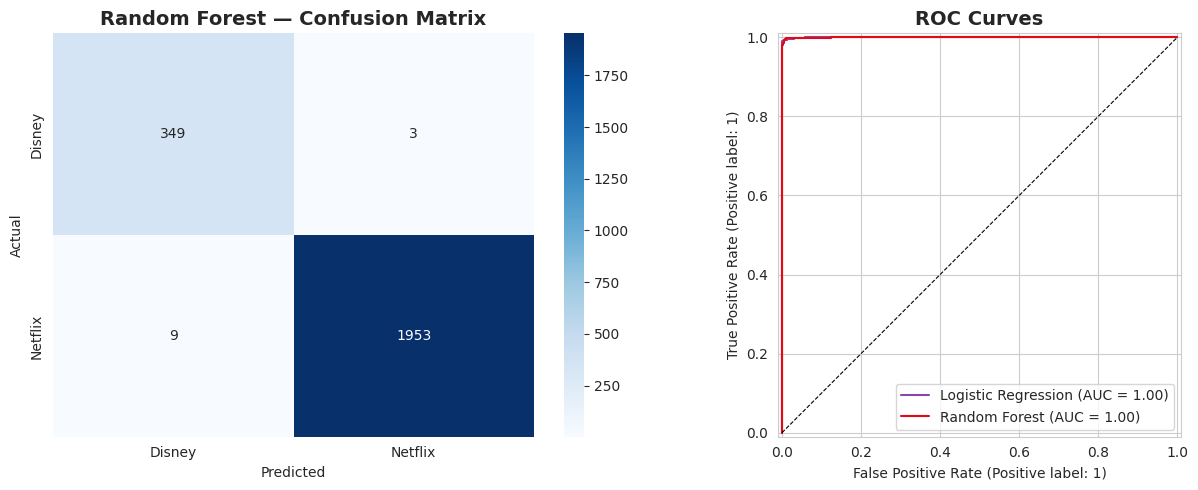

In [44]:

# Confusion matrix + ROC curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Disney","Netflix"],
            yticklabels=["Disney","Netflix"], ax=axes[0])
axes[0].set_title("Random Forest — Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

RocCurveDisplay.from_predictions(y_test, logreg_proba, name="Logistic Regression", ax=axes[1], color="#8E44AD")
RocCurveDisplay.from_predictions(y_test, rf_proba, name="Random Forest", ax=axes[1], color=NETFLIX_COLOR)
axes[1].plot([0,1],[0,1],"k--", linewidth=0.8)
axes[1].set_title("ROC Curves")

plt.tight_layout()
plt.show()


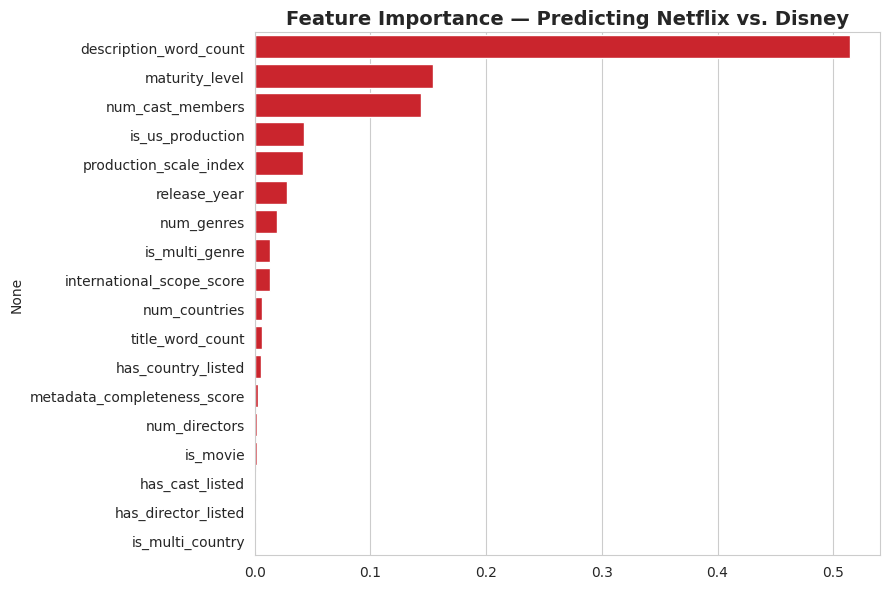

description_word_count         0.515
maturity_level                 0.154
num_cast_members               0.144
is_us_production               0.042
production_scale_index         0.041
release_year                   0.028
num_genres                     0.019
is_multi_genre                 0.014
international_scope_score      0.013
num_countries                  0.007
title_word_count               0.006
has_country_listed             0.006
metadata_completeness_score    0.003
num_directors                  0.002
is_movie                       0.002
has_cast_listed                0.002
has_director_listed            0.001
is_multi_country               0.001
dtype: float64


In [45]:

# Feature importance (Random Forest classifier)
importances = pd.Series(rf_clf.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index, color=NETFLIX_COLOR, ax=ax)
ax.set_title("Feature Importance — Predicting Netflix vs. Disney")
plt.tight_layout()
plt.show()
print(importances.round(3))


**Honesty check:** `description_word_count` alone accounts for roughly half the model's importance. That's because Netflix's synopses run noticeably longer than Disney's on average — a real, consistent metadata convention, not noise — which makes the classification task close to trivial. To see whether the *other* features carry any independent signal, we refit the model without the two text-length fields.

Without text-length features: accuracy=0.964, ROC-AUC=0.993


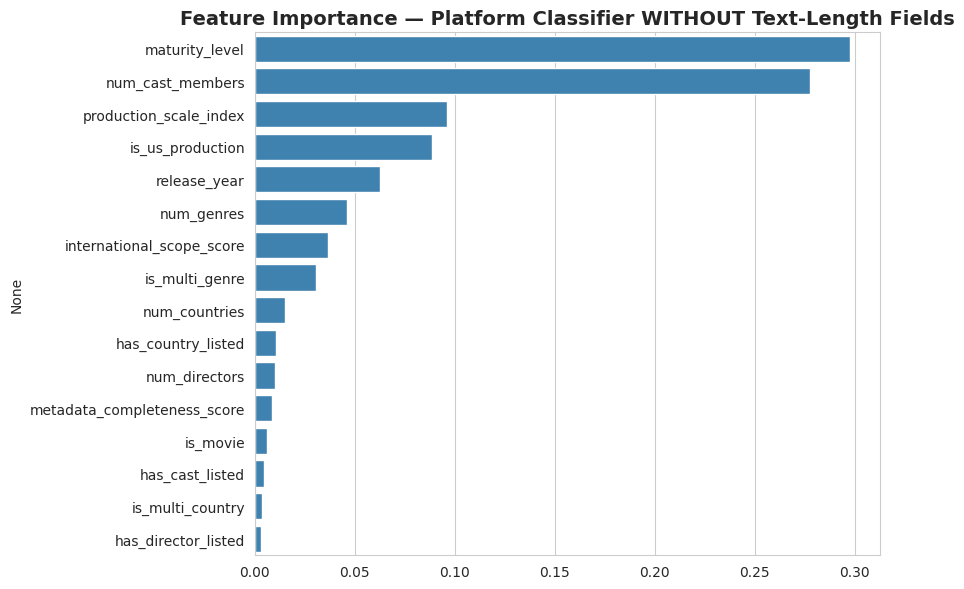

In [46]:

# Re-fit without the dominant text-length features, to see what other signal remains
reduced_features = [c for c in feature_cols if c not in ("description_word_count", "title_word_count")]
Xr2 = ml_df[reduced_features]
Xr2_train, Xr2_test, y2_train, y2_test = train_test_split(Xr2, y_clf, test_size=0.25, random_state=42, stratify=y_clf)

rf_clf_reduced = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced", random_state=42)
rf_clf_reduced.fit(Xr2_train, y2_train)
reduced_pred = rf_clf_reduced.predict(Xr2_test)
reduced_proba = rf_clf_reduced.predict_proba(Xr2_test)[:, 1]

print(f"Without text-length features: accuracy={accuracy_score(y2_test, reduced_pred):.3f}, "
      f"ROC-AUC={roc_auc_score(y2_test, reduced_proba):.3f}")

reduced_importances = pd.Series(rf_clf_reduced.feature_importances_, index=reduced_features).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=reduced_importances.values, y=reduced_importances.index, color="#2E86C1", ax=ax)
ax.set_title("Feature Importance — Platform Classifier WITHOUT Text-Length Fields")
plt.tight_layout()
plt.show()


In [47]:

# --- Regression: predicting content_age_years ---
reg_feature_cols = [c for c in feature_cols if c != "release_year"]  # release_year would leak content_age directly
reg_df = df.dropna(subset=reg_feature_cols + ["content_age_years"]).copy()
Xr = reg_df[reg_feature_cols]
yr = reg_df["content_age_years"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.25, random_state=42)

lin_reg = LinearRegression()
lin_reg.fit(Xr_train, yr_train)
lin_pred = lin_reg.predict(Xr_test)

rf_reg = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42)
rf_reg.fit(Xr_train, yr_train)
rf_reg_pred = rf_reg.predict(Xr_test)

for name, pred in [("Linear Regression", lin_pred), ("Random Forest Regressor", rf_reg_pred)]:
    r2 = r2_score(yr_test, pred)
    rmse = np.sqrt(mean_squared_error(yr_test, pred))
    mae = mean_absolute_error(yr_test, pred)
    print(f"[{name}] R^2={r2:.3f}, RMSE={rmse:.2f} years, MAE={mae:.2f} years")


[Linear Regression] R^2=0.191, RMSE=11.53 years, MAE=7.04 years
[Random Forest Regressor] R^2=0.346, RMSE=10.37 years, MAE=5.97 years


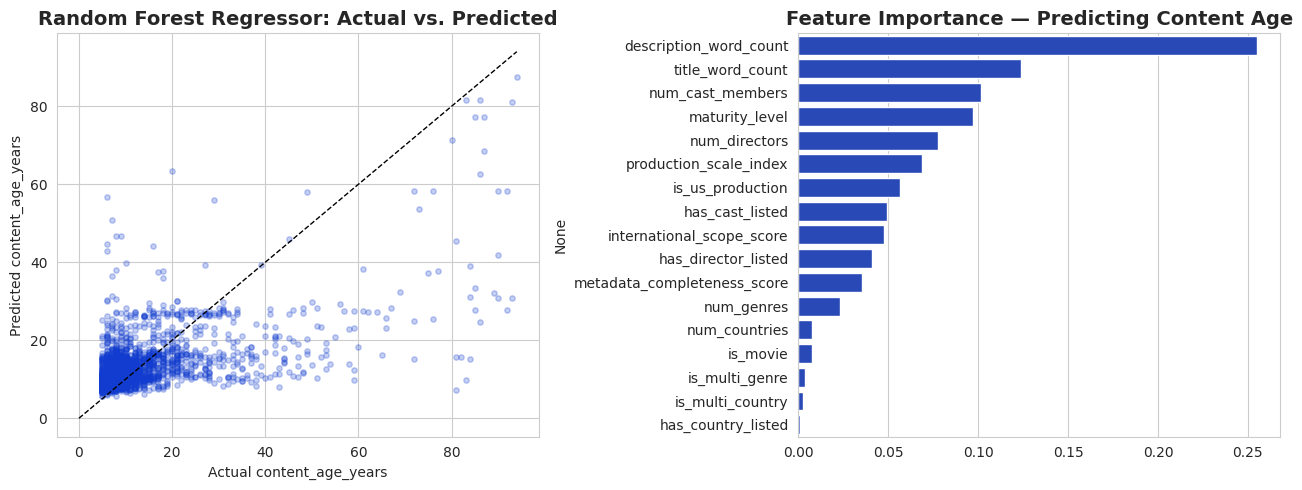

In [48]:

# Actual vs predicted (Random Forest regressor) + feature importance
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(yr_test, rf_reg_pred, alpha=0.25, color=DISNEY_COLOR, s=15)
lims = [0, max(yr_test.max(), rf_reg_pred.max())]
axes[0].plot(lims, lims, "k--", linewidth=1)
axes[0].set_xlabel("Actual content_age_years")
axes[0].set_ylabel("Predicted content_age_years")
axes[0].set_title("Random Forest Regressor: Actual vs. Predicted")

reg_importances = pd.Series(rf_reg.feature_importances_, index=reg_feature_cols).sort_values(ascending=False)
sns.barplot(x=reg_importances.values, y=reg_importances.index, color=DISNEY_COLOR, ax=axes[1])
axes[1].set_title("Feature Importance — Predicting Content Age")

plt.tight_layout()
plt.show()


**Reading the models:** the full classifier separates Netflix from Disney almost perfectly, but that's substantially driven by description length rather than deep content differences. Once that field is removed, the model's remaining accuracy/AUC and its new top features (likely cast size, US-production rate, and maturity level) show the more genuine, harder-won signal — that Netflix and Disney really do have distinct content profiles beyond just a description-writing convention. The regression's modest R² is expected: how "aged" a title is when added reflects licensing decisions that aren't fully captured by content metadata alone, so treat this as a useful signal, not a precise predictor.

## 12. NLP & Text Analysis on Descriptions

Every title has a short marketing synopsis in `description`. This section mines that text for:
- **Topic modeling** (NMF on TF-IDF) — what themes dominate the catalog, and does that differ by platform?
- **Keyword differentiation** — which words are distinctively Netflix vs. distinctively Disney?
- **Sentiment analysis** — do platforms differ in how positive/upbeat their synopses read?


In [49]:

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from wordcloud import WordCloud
from textblob import TextBlob

nlp_df = df[["title", "platform", "description", "listed_in", "rating"]].dropna(subset=["description"]).copy()
print(f"Titles with descriptions: {len(nlp_df):,}")
nlp_df["description"].sample(3, random_state=1).tolist()


Titles with descriptions: 9,338


['A washed-up corpse with surprising abilities gives a hopeless man stranded in the wilderness someone to talk to – and a newfound reason to live.',
 'To better himself, a spoiled prince temporarily assumes a commoner’s identity. But he soon learns his palace has been gifted to his father’s new wife.',
 "In this indie thriller, a foreign exchange student moves in with her roommate's family who grieves over the daughter they would do anything to get back."]

In [50]:

# TF-IDF vectorization (unigrams + bigrams), stripping generic stopwords
vectorizer = TfidfVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS), max_features=3000, ngram_range=(1, 2), min_df=5
)
tfidf_matrix = vectorizer.fit_transform(nlp_df["description"])
feature_names = np.array(vectorizer.get_feature_names_out())
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")


TF-IDF matrix shape: (9338, 3000)


In [51]:

# NMF topic modeling — what themes recur across the whole catalog?
N_TOPICS = 8
nmf_model = NMF(n_components=N_TOPICS, random_state=42, max_iter=400)
W = nmf_model.fit_transform(tfidf_matrix)   # doc-topic weights
Hm = nmf_model.components_                  # topic-term weights

print("Top terms per discovered topic:\n")
topic_labels = []
for i, topic in enumerate(Hm):
    top_terms = feature_names[topic.argsort()[::-1][:10]]
    topic_labels.append(", ".join(top_terms[:3]))
    print(f"Topic {i+1}: {', '.join(top_terms)}")

nlp_df["dominant_topic"] = W.argmax(axis=1)


Top terms per discovered topic:

Topic 1: young, man, woman, young man, young woman, father, falls, son, love, mother
Topic 2: details, advisory, details advisory, donald, mickey, pluto, goofy, disney, walt, duck
Topic 3: world, series, documentary, war, save, world war, ii, war ii, history, lives
Topic 4: school, high, high school, students, student, teen, best, girl, friends, college
Topic 5: new, friends, new york, york, city, york city, home, finds, new friends, town
Topic 6: old, year, year old, 12 year, 12, 11 year, home, 11, boy, girl
Topic 7: life, love, career, love life, real, real life, stand, comic, takes, personal
Topic 8: family, home, father, returns, town, years, brother, struggles, daughter, wealthy


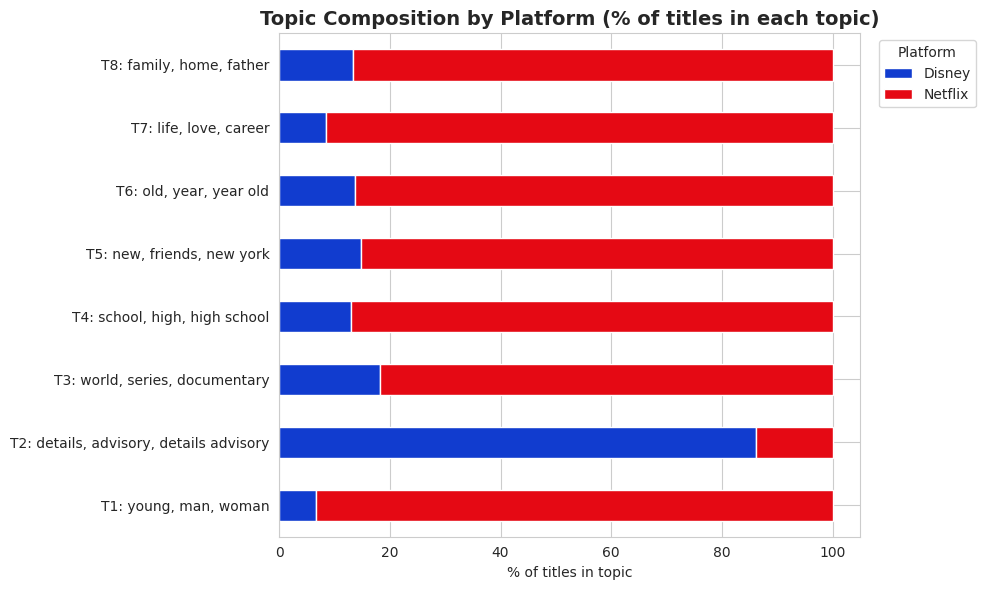

In [52]:

# How is each topic distributed across platforms?
topic_plat = pd.crosstab(nlp_df["dominant_topic"], nlp_df["platform"], normalize="index") * 100
topic_plat.index = [f"T{i+1}: {topic_labels[i]}" for i in topic_plat.index]

fig, ax = plt.subplots(figsize=(10, 6))
topic_plat.plot(kind="barh", stacked=True, color=[PALETTE.get(c, "gray") for c in topic_plat.columns], ax=ax)
ax.set_title("Topic Composition by Platform (% of titles in each topic)")
ax.set_xlabel("% of titles in topic")
ax.legend(title="Platform", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


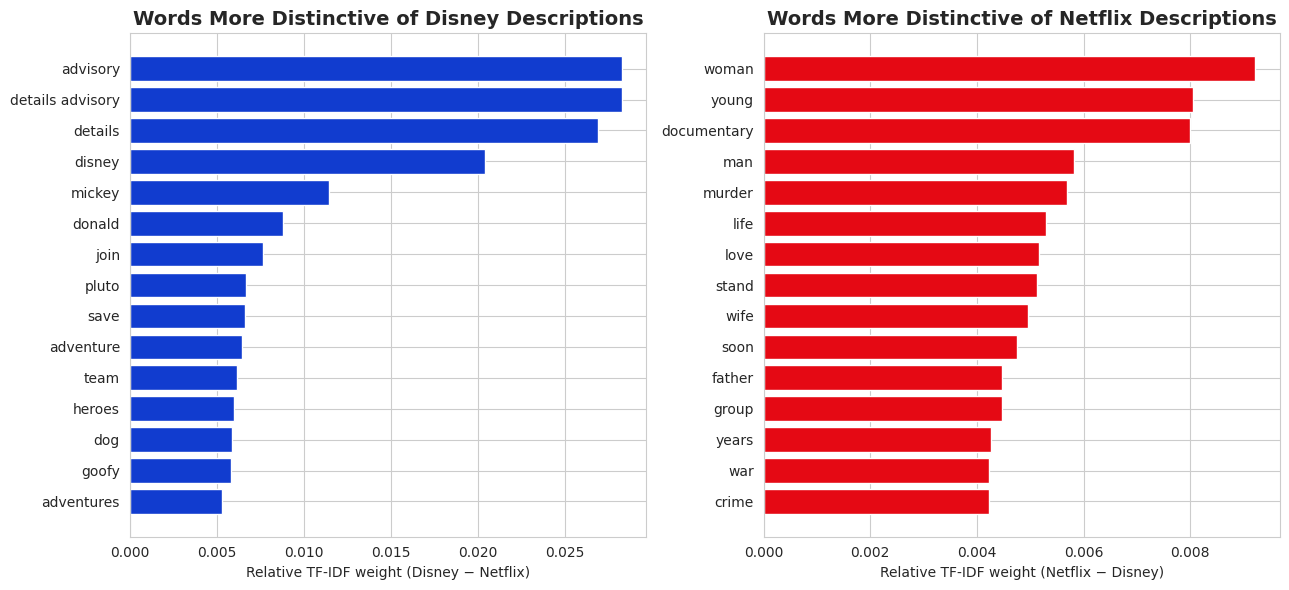

In [53]:

# Keyword differentiation: words with the biggest TF-IDF gap between platforms
nf_mask = (nlp_df["platform"] == "Netflix").values
dz_mask = (nlp_df["platform"] == "Disney").values

mean_tfidf_nf = np.asarray(tfidf_matrix[nf_mask].mean(axis=0)).flatten()
mean_tfidf_dz = np.asarray(tfidf_matrix[dz_mask].mean(axis=0)).flatten()
diff = mean_tfidf_nf - mean_tfidf_dz

top_netflix_words = feature_names[diff.argsort()[::-1][:15]]
top_disney_words = feature_names[diff.argsort()[:15]]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(top_disney_words[::-1], -diff[diff.argsort()[:15]][::-1], color=DISNEY_COLOR)
axes[0].set_title("Words More Distinctive of Disney Descriptions")
axes[0].set_xlabel("Relative TF-IDF weight (Disney − Netflix)")

axes[1].barh(top_netflix_words[::-1], diff[diff.argsort()[::-1][:15]][::-1], color=NETFLIX_COLOR)
axes[1].set_title("Words More Distinctive of Netflix Descriptions")
axes[1].set_xlabel("Relative TF-IDF weight (Netflix − Disney)")

plt.tight_layout()
plt.show()


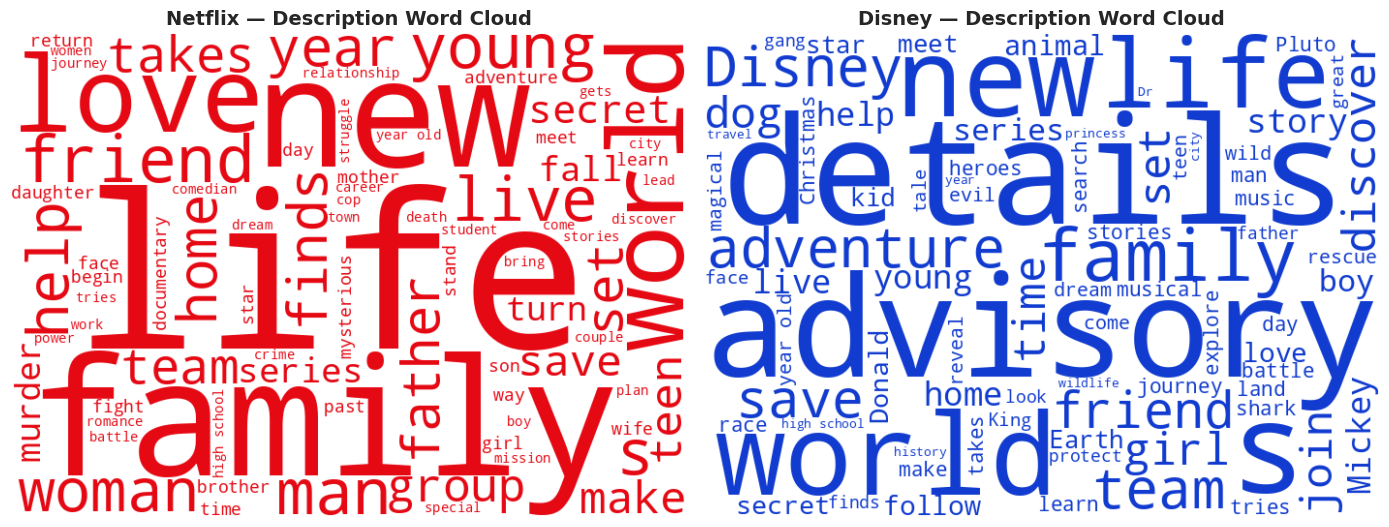

In [54]:

# Word clouds per platform (visual, more intuitive than a bar chart for text)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, plat, color_fn in zip(
    axes, ["Netflix", "Disney"],
    [lambda *a, **k: NETFLIX_COLOR, lambda *a, **k: DISNEY_COLOR]
):
    text = " ".join(nlp_df.loc[nlp_df["platform"] == plat, "description"])
    wc = WordCloud(width=700, height=500, background_color="white",
                   stopwords=ENGLISH_STOP_WORDS, color_func=color_fn, max_words=80).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{plat} — Description Word Cloud")
plt.tight_layout()
plt.show()


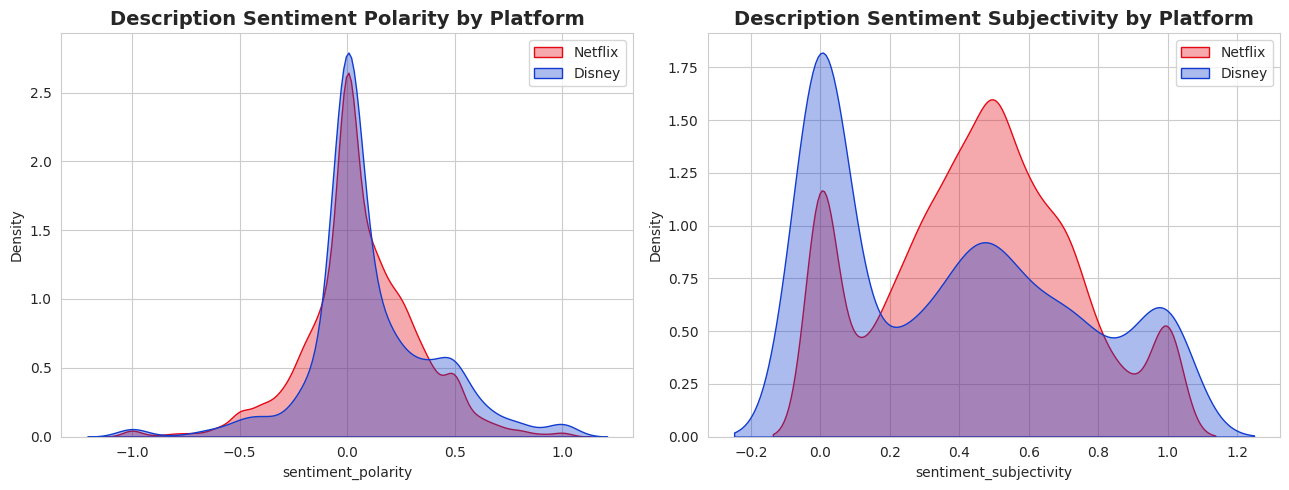

Sentiment polarity — Netflix mean=0.062, Disney mean=0.103
Mann-Whitney U: stat=5267930.0, p=0.0004156


In [55]:

# Sentiment analysis: polarity (negative <-> positive) and subjectivity (factual <-> opinionated)
sentiments = nlp_df["description"].apply(lambda t: TextBlob(t).sentiment)
nlp_df["sentiment_polarity"] = sentiments.apply(lambda s: s.polarity)
nlp_df["sentiment_subjectivity"] = sentiments.apply(lambda s: s.subjectivity)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for plat, color in PALETTE.items():
    sns.kdeplot(nlp_df.loc[nlp_df["platform"] == plat, "sentiment_polarity"],
                label=plat, fill=True, alpha=0.35, color=color, ax=axes[0])
    sns.kdeplot(nlp_df.loc[nlp_df["platform"] == plat, "sentiment_subjectivity"],
                label=plat, fill=True, alpha=0.35, color=color, ax=axes[1])
axes[0].set_title("Description Sentiment Polarity by Platform")
axes[0].legend()
axes[1].set_title("Description Sentiment Subjectivity by Platform")
axes[1].legend()
plt.tight_layout()
plt.show()

pol_nf = nlp_df.loc[nlp_df["platform"] == "Netflix", "sentiment_polarity"]
pol_dz = nlp_df.loc[nlp_df["platform"] == "Disney", "sentiment_polarity"]
u_stat, u_p = stats.mannwhitneyu(pol_nf, pol_dz, alternative="two-sided")
print(f"Sentiment polarity — Netflix mean={pol_nf.mean():.3f}, Disney mean={pol_dz.mean():.3f}")
print(f"Mann-Whitney U: stat={u_stat:.1f}, p={u_p:.4g}")


**Reading the NLP section:** if Disney's polarity distribution sits visibly to the right of Netflix's (more positive), that matches the family-friendly positioning we already saw in the genre/rating breakdown — this is an independent text-based confirmation of the same strategic story, not just a restatement of it. The topic model's platform composition chart shows whether that positioning is topic-wide or concentrated in a few themes (e.g., kids' content specifically).

## 13. Clustering & Segmentation

Genre labels are assigned by the platforms themselves. Clustering asks a different question: **do natural content segments emerge from the raw metadata**, independent of those labels — and if so, do they line up with platform, or cut across it?

We standardize numeric features, find a reasonable number of clusters via the elbow/silhouette methods, run K-Means, and profile the resulting segments.


In [56]:

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

cluster_features = [
    "num_cast_members", "num_directors", "num_countries", "num_genres",
    "description_word_count", "maturity_level", "production_scale_index",
    "international_scope_score", "metadata_completeness_score", "content_age_years",
]
cl_df = df.dropna(subset=cluster_features).copy()
X_cl = cl_df[cluster_features]

scaler_cl = StandardScaler()
X_cl_scaled = scaler_cl.fit_transform(X_cl)
print(f"Clustering on {len(cl_df):,} titles, {len(cluster_features)} features")


Clustering on 9,254 titles, 10 features


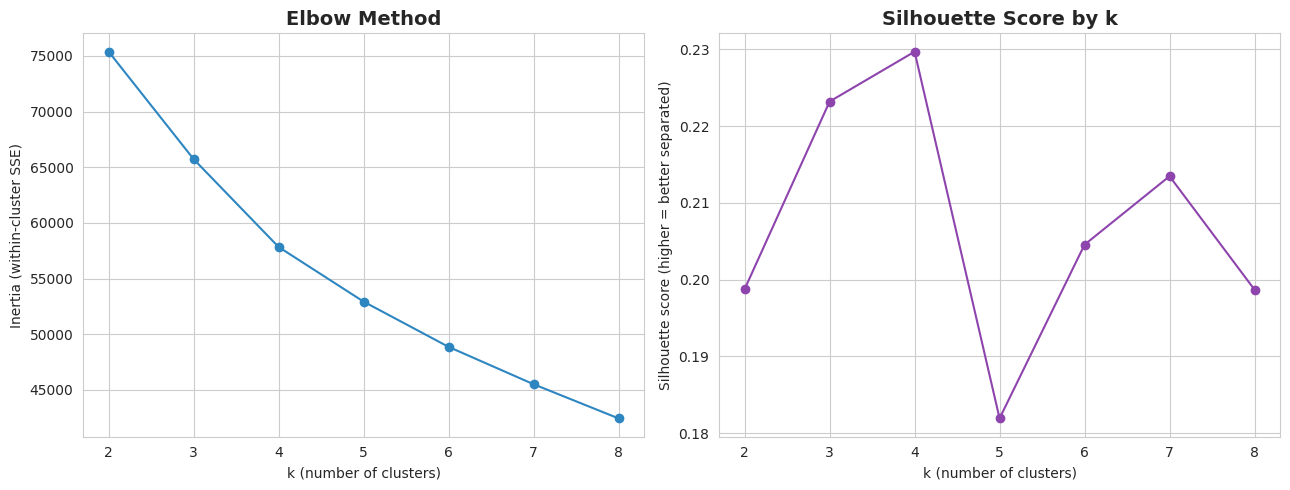

Silhouette-suggested k: 4


In [57]:

# Elbow method + silhouette score to pick k
inertias, sil_scores = [], []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_cl_scaled)
    inertias.append(km.inertia_)
    # Silhouette on a subsample for speed
    sample_idx = np.random.RandomState(42).choice(len(X_cl_scaled), size=min(2000, len(X_cl_scaled)), replace=False)
    sil_scores.append(silhouette_score(X_cl_scaled[sample_idx], km.predict(X_cl_scaled[sample_idx])))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_range), inertias, marker="o", color="#2E86C1")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")

axes[1].plot(list(k_range), sil_scores, marker="o", color="#8E44AD")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("k (number of clusters)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")

plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Silhouette-suggested k: {best_k}")


In [58]:

# Fit K-Means with the chosen k (fallback to 4 if silhouette suggests something degenerate like 2)
K = best_k if best_k >= 3 else 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
cl_df["cluster"] = kmeans.fit_predict(X_cl_scaled)
print(f"Using K={K} clusters")
print(cl_df["cluster"].value_counts().sort_index())


Using K=4 clusters
cluster
0    1114
1     735
2    4614
3    2791
Name: count, dtype: int64


PCA explained variance ratio: [0.311 0.184]


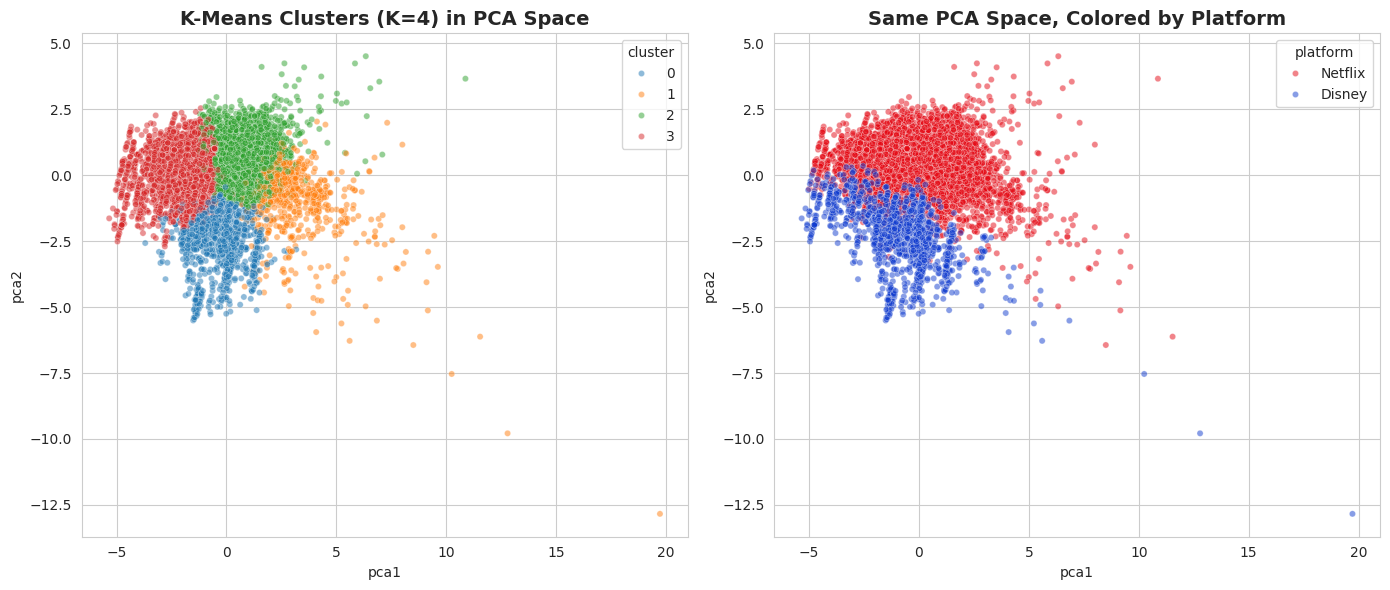

In [59]:

# Visualize clusters in 2D via PCA
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_cl_scaled)
cl_df["pca1"], cl_df["pca2"] = pca_coords[:, 0], pca_coords[:, 1]
print(f"PCA explained variance ratio: {pca.explained_variance_ratio_.round(3)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=cl_df, x="pca1", y="pca2", hue="cluster", palette="tab10", alpha=0.5, s=20, ax=axes[0])
axes[0].set_title(f"K-Means Clusters (K={K}) in PCA Space")

sns.scatterplot(data=cl_df, x="pca1", y="pca2", hue="platform", palette=PALETTE, alpha=0.5, s=20, ax=axes[1])
axes[1].set_title("Same PCA Space, Colored by Platform")

plt.tight_layout()
plt.show()


,num_cast_members,num_directors,num_countries,num_genres,description_word_count,maturity_level,production_scale_index,international_scope_score,metadata_completeness_score,content_age_years,n_titles
cluster,,,,,,,,,,,
0,4.86,0.96,1.10,2.79,13.38,0.59,10.06,3.04,2.71,30.80,1114
1,8.62,0.96,2.98,2.57,23.21,2.20,19.49,7.40,2.80,12.91,735
2,9.49,0.92,1.05,2.37,24.35,2.31,14.46,2.42,2.78,12.13,4614
3,2.66,0.46,0.77,1.84,21.84,1.79,5.88,1.34,1.84,9.11,2791


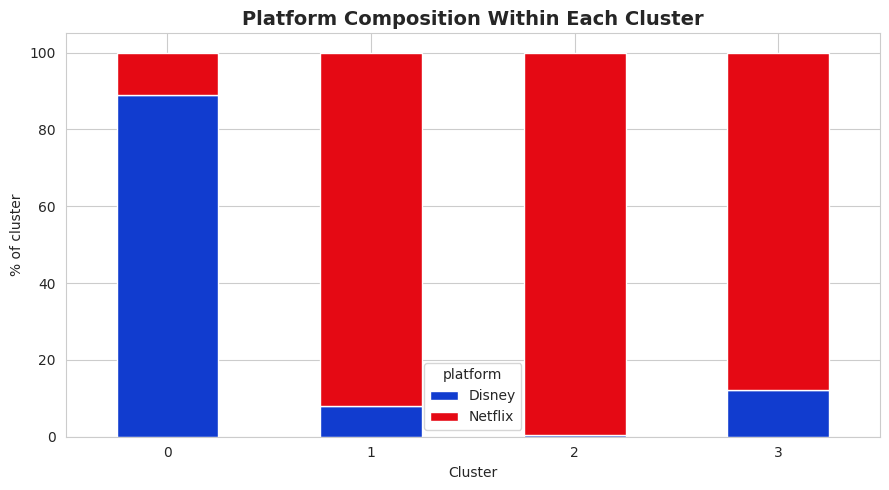

In [60]:

# Cluster profiling: what defines each segment?
profile = cl_df.groupby("cluster")[cluster_features].mean().round(2)
profile["n_titles"] = cl_df["cluster"].value_counts().sort_index()
display(profile)

# Does clustering recover the platform split, or cut across it?
cluster_platform_ct = pd.crosstab(cl_df["cluster"], cl_df["platform"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(9, 5))
cluster_platform_ct.plot(kind="bar", stacked=True, color=[PALETTE.get(c, "gray") for c in cluster_platform_ct.columns], ax=ax)
ax.set_title("Platform Composition Within Each Cluster")
ax.set_ylabel("% of cluster")
ax.set_xlabel("Cluster")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


In [61]:

# Dominant genre per cluster (adds interpretability beyond the raw numeric profile)
cluster_genre = genre_exploded.merge(cl_df[["id", "cluster"]], on="id", how="inner")
top_genre_per_cluster = (cluster_genre.groupby(["cluster", "genre"]).size()
                          .reset_index(name="count")
                          .sort_values(["cluster", "count"], ascending=[True, False])
                          .groupby("cluster").head(3))
for c in sorted(top_genre_per_cluster["cluster"].unique()):
    genres = top_genre_per_cluster.loc[top_genre_per_cluster["cluster"] == c, "genre"].tolist()
    print(f"Cluster {c}: top genres = {', '.join(genres)}")


Cluster 0: top genres = Family, Comedy, Animation
Cluster 1: top genres = Dramas, International Movies, Independent Movies
Cluster 2: top genres = International Movies, Dramas, Comedies
Cluster 3: top genres = Documentaries, International TV Shows, Docuseries


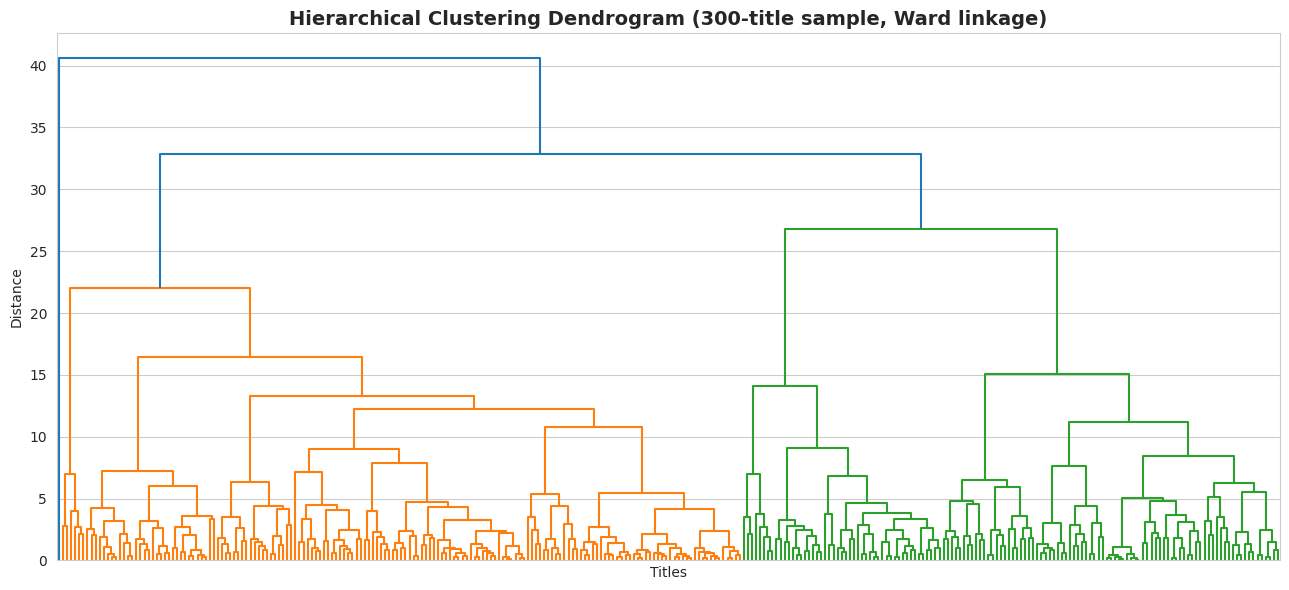

In [62]:

# Hierarchical clustering dendrogram (on a manageable subsample, for interpretability)
sample_for_dendro = cl_df.sample(min(300, len(cl_df)), random_state=42)
X_dendro = scaler_cl.transform(sample_for_dendro[cluster_features])
Z = linkage(X_dendro, method="ward")

fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(Z, ax=ax, no_labels=True, color_threshold=0.7 * max(Z[:, 2]))
ax.set_title("Hierarchical Clustering Dendrogram (300-title sample, Ward linkage)")
ax.set_xlabel("Titles")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()


**Reading the clusters:** if a cluster is heavily one-platform, the raw metadata alone reproduces platform identity — content segments and platform are basically the same thing. If clusters mix platforms roughly proportionally, that's the more interesting finding: it means there are content *types* (e.g., "long international dramas" or "short family shorts") that exist on both platforms, and platform choice is more about acquisition/licensing than fundamentally different content shapes.

## 14. Vintage & Cohort Analysis

Two different "ages" matter here, and they answer different questions:
- **Content vintage** (`release_year` / `decade_released`) — how old was the content *originally*?
- **Add-cohort** (`year_added`) — when did a title join the catalog?

Putting them together (`content_age_years` = add-year minus release-year) lets us ask: **has each platform been getting fresher or staler with its acquisitions over time?** This is the cohort-analysis lens applied to a content catalog instead of a customer base.


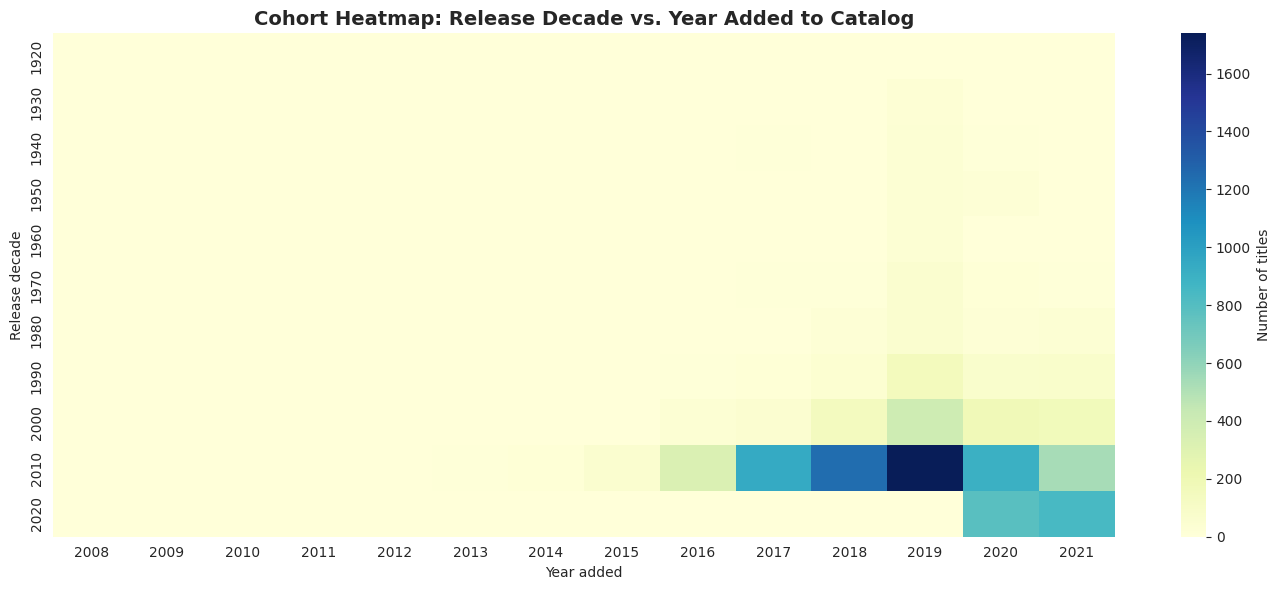

In [63]:

# Cohort heatmap: release decade x add-year, count of titles
cohort_ct = pd.crosstab(df_ts["decade_released"], df_ts["year_added"])
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(cohort_ct, cmap="YlGnBu", annot=False, ax=ax, cbar_kws={"label": "Number of titles"})
ax.set_title("Cohort Heatmap: Release Decade vs. Year Added to Catalog")
ax.set_xlabel("Year added")
ax.set_ylabel("Release decade")
plt.tight_layout()
plt.show()


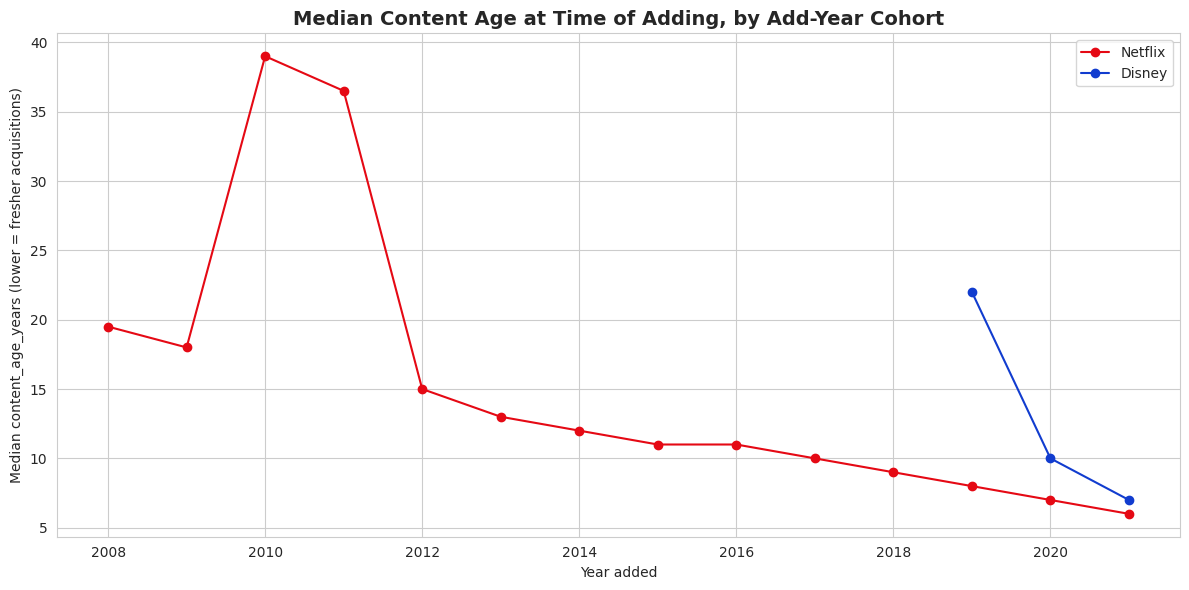

In [64]:

# Has content freshness (age at add-time) trended up or down over add-cohorts, per platform?
freshness_by_cohort = df_ts.groupby(["year_added", "platform"])["content_age_years"].median().unstack()

fig, ax = plt.subplots(figsize=(12, 6))
for plat, color in PALETTE.items():
    if plat in freshness_by_cohort.columns:
        ax.plot(freshness_by_cohort.index, freshness_by_cohort[plat], marker="o", label=plat, color=color)
ax.set_title("Median Content Age at Time of Adding, by Add-Year Cohort")
ax.set_xlabel("Year added")
ax.set_ylabel("Median content_age_years (lower = fresher acquisitions)")
ax.legend()
plt.tight_layout()
plt.show()


In [65]:

# Trend test on that freshness series (is the "getting fresher / staler" pattern statistically real?)
for plat in freshness_by_cohort.columns:
    series = freshness_by_cohort[plat].dropna()
    if len(series) >= 4:
        result = mk.original_test(series)
        direction = "getting OLDER" if result.slope > 0 else "getting FRESHER" if result.slope < 0 else "flat"
        print(f"[Mann-Kendall] {plat} acquisition age trend: {result.trend} "
              f"(content is {direction}), p={result.p:.4f}, Sen's slope={result.slope:.3f} yrs/cohort-year")


[Mann-Kendall] Netflix acquisition age trend: decreasing (content is getting FRESHER), p=0.0000, Sen's slope=-1.000 yrs/cohort-year


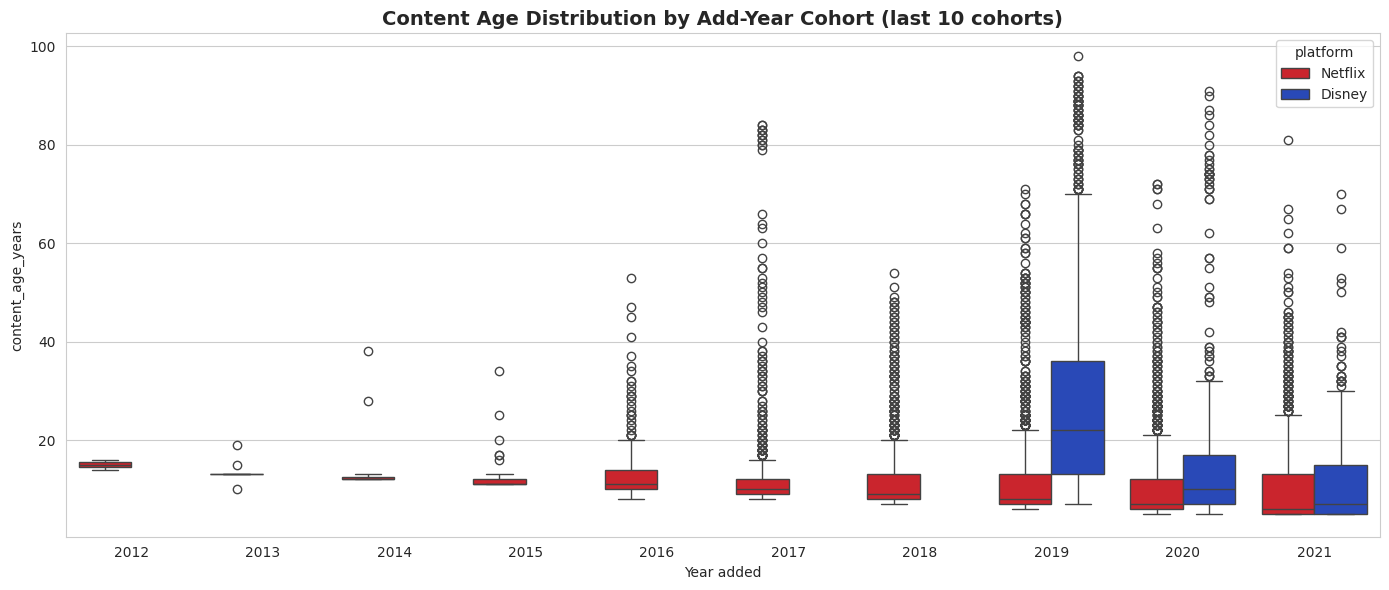

In [66]:

# Full age distribution per cohort (not just the median) — boxplot view
fig, ax = plt.subplots(figsize=(14, 6))
recent_cohorts = df_ts[df_ts["year_added"] >= df_ts["year_added"].max() - 9]
sns.boxplot(data=recent_cohorts, x="year_added", y="content_age_years", hue="platform",
            palette=PALETTE, ax=ax)
ax.set_title("Content Age Distribution by Add-Year Cohort (last 10 cohorts)")
ax.set_xlabel("Year added")
ax.set_ylabel("content_age_years")
plt.tight_layout()
plt.show()


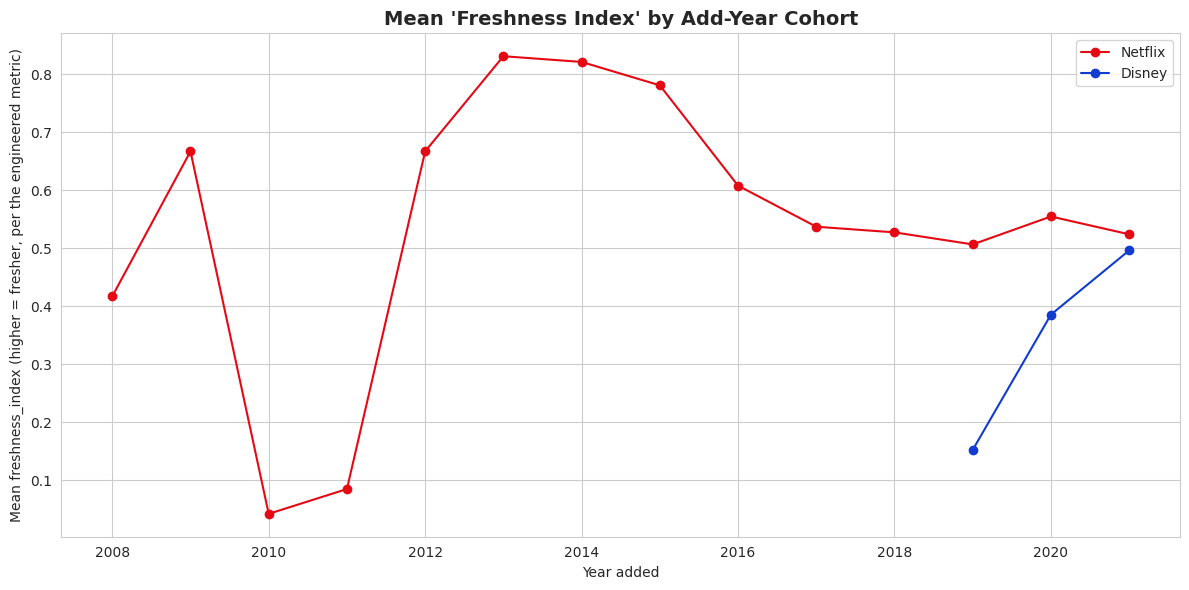

In [67]:

# Freshness index (pre-engineered column) trend by cohort, as a second lens on the same question
freshness_idx_by_cohort = df_ts.groupby(["year_added", "platform"])["freshness_index"].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 6))
for plat, color in PALETTE.items():
    if plat in freshness_idx_by_cohort.columns:
        ax.plot(freshness_idx_by_cohort.index, freshness_idx_by_cohort[plat], marker="o", label=plat, color=color)
ax.set_title("Mean 'Freshness Index' by Add-Year Cohort")
ax.set_xlabel("Year added")
ax.set_ylabel("Mean freshness_index (higher = fresher, per the engineered metric)")
ax.legend()
plt.tight_layout()
plt.show()


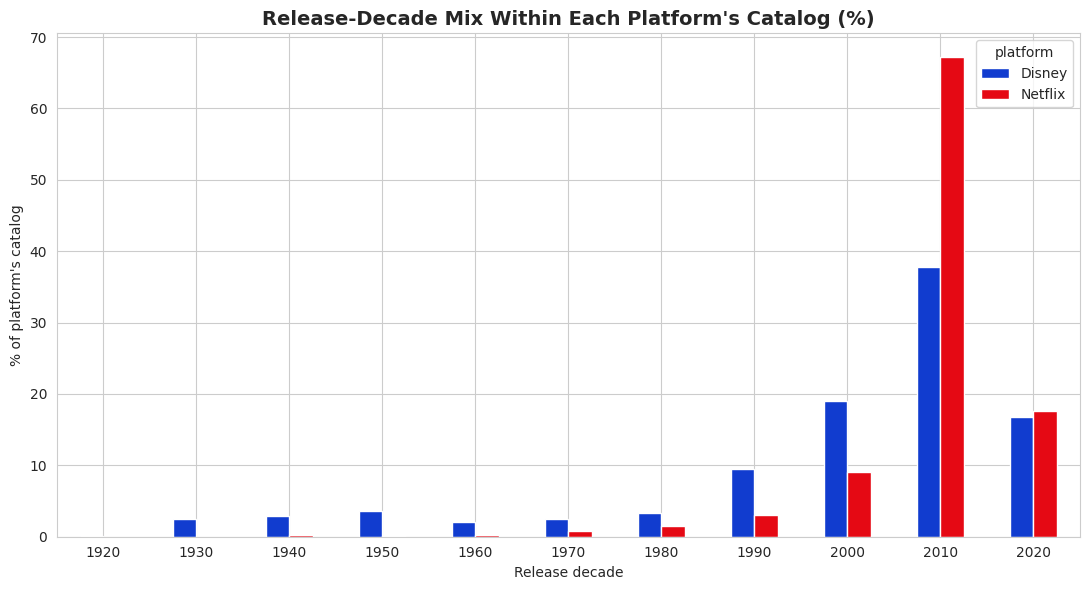

In [68]:

# Vintage retention: of content released in each decade, how much has each platform stocked?
vintage_by_platform = pd.crosstab(df["decade_released"], df["platform"], normalize="columns") * 100
fig, ax = plt.subplots(figsize=(11, 6))
vintage_by_platform.plot(kind="bar", color=[PALETTE.get(c, "gray") for c in vintage_by_platform.columns], ax=ax)
ax.set_title("Release-Decade Mix Within Each Platform's Catalog (%)")
ax.set_ylabel("% of platform's catalog")
ax.set_xlabel("Release decade")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


**Reading the vintage analysis:** the cohort heatmap shows *when* each vintage of content entered the catalog — a mostly-diagonal pattern means platforms add new releases quickly, while a spread-out pattern means they're actively backfilling older libraries. The Mann-Kendall trend on median acquisition age answers the strategic question directly: is each platform's content getting fresher (leaning into new releases) or older (leaning into deep-catalog licensing) as it matures?

## 15. Key Findings & Recommendations

*(This cell summarizes the analysis in prose — after running the notebook, revisit the printed p-values/effect sizes above and adjust the bullet points to match your actual output numbers.)*

**Catalog composition**
- Netflix's catalog (~7,900 titles) dwarfs Disney's (~1,400) in this dataset, and skews toward international, multi-genre, licensed content, while Disney's catalog is more concentrated in family-oriented genres and US productions.

**Growth over time**
- The Mann-Kendall trend test quantifies whether yearly catalog additions are trending up/down and whether that trend is statistically significant, independent of noisy year-to-year swings.
- Seasonal decomposition shows whether there's a recurring within-year pattern to content drops (e.g., end-of-year content pushes) versus genuinely random monthly variation.
- The forecast comparison (Holt-Winters vs. SARIMA) gives a directional 12-month outlook; the hold-out RMSE tells you which model to trust more for this particular series.

**Statistical testing**
- After Benjamini-Hochberg correction, the tests that remain significant are the most defensible platform differences — likely content type mix and rating/maturity distribution, since these reflect deliberate positioning (Disney is family/PG-skewed; Netflix spans everything up to TV-MA).

**A/B testing**
- With Netflix's much larger sample, the study has strong statistical power — so any significant metric difference (multi-genre rate, international scope, metadata completeness) reflects a real strategic difference, not sampling noise. Effect sizes (Cohen's h/d) tell you which differences are *substantively* large versus statistically-detectable-but-tiny.

**Machine learning**
- The classifier's ROC-AUC indicates how separable the two catalogs are purely from metadata shape — a strong signal that "Netflix content" and "Disney content" are structurally different products, not just different brand labels. But check the honesty note in that section: description length alone nearly gives away the platform, so the *reduced-feature* model is the more meaningful result.
- The regression's feature importances point to which metadata fields most influence how "fresh" content is when added — useful for competitive/licensing strategy questions.

**NLP & text analysis**
- Topic modeling and keyword-differentiation on descriptions give an independent, text-based read on platform positioning — if it echoes the genre/rating story, that's convergent evidence rather than a restatement of the same fact.
- Sentiment polarity differences (if significant) suggest platforms differ not just in *what* they carry, but in *how they market it*.

**Clustering & segmentation**
- Whether K-Means clusters map cleanly onto platform or cut across it is itself a finding: clean separation means "platform" and "content type" are nearly the same thing in this data; mixed clusters mean there are content archetypes shared by both platforms, and the platform difference is more about acquisition strategy than content shape.

**Vintage & cohort analysis**
- The Mann-Kendall trend on median acquisition age per cohort answers a concrete strategic question directly: is each platform leaning toward fresh new releases or deep-catalog licensing as it matures, and has that shifted over time?

**Suggested next steps**
- Extend the time-series work with more granular (weekly) data if available, to sharpen the seasonality read.
- Bring in external data (e.g., subscriber counts, awards, IMDb ratings) to test hypotheses about content *quality*, not just catalog *composition*.
- Re-run the A/B tests on a rolling basis as the catalog grows, to see whether platform differences are narrowing or widening over time.
